# Weekly Cross-Sectional Cryptocurrency Momentum
## Know When to Hodl 'Em, Know When to Fodl 'Em — Hubrich (2017)

**Strategy family: weekly cryptocurrency momentum.** The central idea is to measure whether each coin has recently been strong or weak, either compare that return directly with the other coins or place it in the context of the coin's own history, and translate the result into a small weekly long-short portfolio.

This notebook isolates the paper's weekly momentum idea rather than attempting to reproduce its broader factor study. Momentum is the prior seven-calendar-day return for each currency.

Here is the trading process:

1. **Measure recent momentum.** For every coin, calculate the previous seven-day return.

2. **Put the signal in context.** A **Cross-Sectional** score compares each coin's raw seven-day return directly with the other 29 coins. A **Complete** score separately asks whether a coin's current momentum is unusual relative to its own prior history.

3. **Choose a weighting rule.** Equal weighting gives comparable active weight to each signal; risk weighting scales positions by volatility. Each standalone factor targets 10% gross exposure. Cash earns zero; its ledger balance depends on the signed long and short positions.

4. **Rebalance weekly.** The notebook runs seven otherwise identical accounts—one for each possible formation weekday—so a favorable result cannot depend on choosing one convenient weekday.

5. **Pay implementation costs.** Positions are held in actual units between trades and incur 20 basis points per traded dollar, including the final liquidation of each test segment.

6. **Compare fairly.** Every construction uses the same 30 coins, the same daily closing-price history, and the same backtest and validation dates. Parameters are selected only in backtest and then frozen for validation.

The main research question is whether Hubrich's four momentum constructions transfer to this fixed modern crypto universe: **Complete** or **Cross-Sectional**, each with **Equal Weighting (EW)** or **Risk Weighting (RW)**.

**Reference:** Hubrich, S. (2017), *“Know when to hodl 'em, know when to fodl 'em”: An Investigation
of Factor Based Investing in the Cryptocurrency Space*.
[Paper record](https://ssrn.com/abstract=3055498) · [DOI](https://doi.org/10.2139/ssrn.3055498).

**Fixed research dates:** prices run from **2021-01-01 through 2026-09-17**. Strategy returns use
the common chronological split: **Backtest 2021-01-02 through 2024-12-31** and **Validation
2025-01-01 through 2026-09-17**. These dates apply to every strategy in the notebook.

Run all cells in order. The common market input is
`OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv`. Market capitalization for the passive
capitalization-weighted benchmark comes from `OHLCV_Market_Cap_Data/crypto_30_coin_daily_market_cap_supply.csv`; both aligned files are
produced by the shared data-download notebook from the same CMC history response.


## 1. Research design and experiment map

The **research universe always contains the same 30 coins** shown below. Every strategy receives
the same closing-price observations from the common OHLCV file. A strategy may temporarily
hold cash when its signal is unavailable, but it cannot add a different coin, change the sample, or
move the backtest/validation boundary.

The core experiment compares the four momentum portfolios with equal-weight, capitalization-weight, and risk-weighted benchmarks at the same 10% target exposure. It also checks two burn-in lengths, all seven weekly schedules, and return-outlier sensitivity.

**Selection rule fixed before evaluation:** among the four standalone momentum constructions with
a 30-observation burn-in, select the highest median net weekly Sharpe across the seven schedules in
the backtest. Exact ties use lower median turnover and then the declared construction order. Freeze
that construction before calculating validation performance. The weekday is never optimized;
Monday is used only for representative daily charts.

This is a controlled test on a prescribed basket. It answers which implementation works best for
these 30 coins over the shared 2021–2026 sample, rather than reconstructing every coin that was
historically investable.


### Configuration and naming guide

These settings define the signal horizon, the amount invested, the trading-cost assumption, the
annualization conventions, and the strategy names used throughout the notebook.

| Setting | Meaning in this study |
|---|---|
| `MOMENTUM_DAYS = 7` | Momentum is the close-to-close return over the previous seven calendar days. A score formed at today's close is used only for subsequent returns. |
| `BURN_INS = [30, 90]` | Expanding means and standard deviations require at least 30 or 90 prior **daily signal observations**. Because a seven-day return is calculated every day, these observations overlap; they are not 30 or 90 independent weeks. The 30-observation version is primary and 90 is a robustness check. |
| `FACTOR_GROSS = 0.10` | A standalone long-short factor targets 10% gross exposure, meaning the absolute long and short weights sum to 0.10. The remaining 90% is unused gross-exposure capacity, not a prescribed cash balance. Cash earns zero and equals NAV minus signed asset holdings. |
| `BENCHMARK_EXPOSURE = 0.10` | Each passive benchmark also invests 10% of capital so its scale is comparable with the standalone factor portfolios. |
| `COST_BPS = 20` | Every dollar traded incurs 20 basis points, or 0.20%, including entries, rebalances, and the final liquidation. |
|`PERIODS_PER_YEAR = 365`, `WEEKLY_PERIODS_PER_YEAR = 365 / 7` | Daily results use 365 periods per year because cryptocurrency trades every calendar day. Weekly results use approximately 52.14 seven-day periods per year. |
| `HAC_LAGS = 20` | Newey–West/HAC inference retains 20 lags. This changes the estimated uncertainty of means and alphas—not portfolio returns or performance metrics—and allows for heteroskedasticity and residual autocorrelation. The value is fixed before reviewing results and is consistent with the other notebooks. |
| `REPRESENTATIVE_WEEKDAY = 0` | Python numbers Monday as zero. Monday is the predeclared formation weekday used for representative daily charts and attribution; it is not selected because of its performance. |


In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from IPython.display import display, Markdown

NOTEBOOK_NAME = "Knowing_When_To_Hold_Stephan_Hubrich.ipynb"
# Input and output paths are relative to the extracted repository folder.
# Open that folder as your IDE project and start the kernel there.
NOTEBOOK_DIR = Path(".")
DATA_DIR = Path("OHLCV_Market_Cap_Data")
OUTPUT_ROOT = Path("output") / "hubrich_factors"

SAMPLE_START = "2021-01-01"
SAMPLE_END = "2026-09-17"
BACKTEST_START, BACKTEST_END = "2021-01-02", "2024-12-31"
VALIDATION_START, VALIDATION_END = "2025-01-01", "2026-09-17"
# Standard 70-30 split consistent across all notebooks in the project.

# Signal horizon and minimum history for the estimates.
MOMENTUM_DAYS = 7  # Trailing close-to-close return measured in calendar days.
BURN_INS = [30, 90]  # Prior daily signal observations: 30 is primary; 90 is robustness.

# Comparable small allocations: gross exposure for factors and long exposure for benchmarks.
FACTOR_GROSS = BENCHMARK_EXPOSURE = 0.10


COST_BPS = 20
COST_RATE = COST_BPS / 10_000
PERIODS_PER_YEAR = 365
WEEKLY_PERIODS_PER_YEAR = 365 / 7


# Dependence control and the predeclared representative formation schedule.
HAC_LAGS = 20  # Newey–West lags used consistently for HAC inference.
# Retaining 20 lags allows residual dependence across the current observation and the previous 20 observations when estimating uncertainty.
# It does not discard 20 observations and does not mean only 20 data points are used.


REPRESENTATIVE_WEEKDAY = 0  # Monday under Python's Monday=0 convention.
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# MOM = momentum; CS/CPL = Cross-Sectional/Complete; EW/RW = equal/risk weighted.
FACTOR_KEYS = ["MOM_CS_EW", "MOM_CS_RW", "MOM_CPL_EW", "MOM_CPL_RW"]

# Matching long-only momentum overlays derived from the four factor constructions.
OVERLAY_KEYS = [k.replace("MOM_", "OVERLAY_") for k in FACTOR_KEYS]

# BM = benchmark; CW = capitalization weighted. BTC is retained as a separate reference.
BENCHMARK_KEYS = ["BM_EW", "BM_CW", "BM_RW", "BM_BTC"]
PRIMARY_BENCHMARKS = ["BM_EW", "BM_CW", "BM_RW"]  # Benchmarks used in alpha tests.
STRATEGIES = FACTOR_KEYS + OVERLAY_KEYS + BENCHMARK_KEYS  # Common simulation list.
ANCHOR_KEY = "MOM_CPL_RW"  # Hubrich's Complete, risk-weighted momentum reference.



LABELS = {
    "MOM_CS_EW":"CS · equal weight", "MOM_CS_RW":"CS · risk weight",
    "MOM_CPL_EW":"Complete · equal weight", "MOM_CPL_RW":"Complete · risk weight",
    "BM_EW":"10% equal-weight benchmark", "BM_CW":"10% cap-weight benchmark",
    "BM_RW":"10% risk-weight benchmark", "BM_BTC":"10% BTC reference",
}
LABELS.update({k.replace("MOM_","OVERLAY_"):"Momentum overlay · "+v
               for k,v in list(LABELS.items()) if k.startswith("MOM_")})

# Consistent colors and chart formatting across factor constructions.

COLORS = {"MOM_CS_EW":"#6d829f", "MOM_CS_RW":"#8555a6", "MOM_CPL_EW":"#d08a35", "MOM_CPL_RW":"#176b87"}
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfd",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#d1d5db", "axes.labelcolor": "#374151", "text.color": "#1f2937",
    "xtick.color": "#64748b", "ytick.color": "#64748b", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "grid.alpha": 0.25,
    "grid.color": "#cbd5e1", "legend.frameon": False,
})
FIGURES = {}

def polish_axis(ax, date_axis=False, zero_line=False):
    ax.grid(axis="y", linewidth=0.6)
    ax.set_axisbelow(True)
    if zero_line:
        ax.axhline(0, color="#64748b", linewidth=0.8, zorder=0)
    if date_axis:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

def show_figure(fig, name, title, subtitle):
    height_points = fig.get_figheight()*72
    fig.text(0.06, 0.99, title, ha="left", va="top", fontsize=15, fontweight="semibold")
    fig.text(0.06, 0.99-23/height_points, subtitle, va="top", fontsize=9, color="#64748b")
    fig.tight_layout(rect=[0.015, 0.015, 0.985, 0.99-43/height_points], w_pad=2.5, h_pad=2.5)
    FIGURES[name] = fig
    plt.show()
    plt.close(fig)

In [2]:
# Fixed 30-coin universe, grouped by economic category
SECTORS = {
    "Store of Value / Benchmark": ["BTC-USD"],
    "Layer 1 Smart Contracts": ["ETH-USD", "SOL-USD", "BNB-USD", "ADA-USD", "AVAX-USD", "DOT-USD", "NEAR-USD", "ATOM-USD", "TRX-USD", "ALGO-USD", "HBAR-USD"],
    "Payments & Legacy": ["XRP-USD", "DOGE-USD", "LTC-USD", "BCH-USD", "ETC-USD", "XLM-USD"],
    "DeFi Protocols": ["AAVE-USD", "MKR-USD", "UNI7083-USD", "CRV-USD", "INJ-USD", "RUNE-USD"],
    "Infrastructure, Storage & Metaverse": ["LINK-USD", "FIL-USD", "VET-USD", "THETA-USD", "SAND-USD", "MANA-USD"]
}

tickers = [t for members in SECTORS.values() for t in members]
ASSETS = sorted("UNI-USD" if t == "UNI7083-USD" else t for t in tickers)
assert len(ASSETS) == len(set(ASSETS)) == 30
display(pd.DataFrame([{"Category": sector, "Coins": ", ".join(t.replace("7083", "").replace("-USD", "") for t in members)}
                      for sector, members in SECTORS.items()]))



,Category,Coins
0,Store of Value / Benchmark,BTC
1,Layer 1 Smart Contracts,"ETH, SOL, BNB, ADA, AVAX, DOT, NEAR, ATOM, TRX..."
2,Payments & Legacy,"XRP, DOGE, LTC, BCH, ETC, XLM"
3,DeFi Protocols,"AAVE, MKR, UNI, CRV, INJ, RUNE"
4,"Infrastructure, Storage & Metaverse","LINK, FIL, VET, THETA, SAND, MANA"


In [3]:
# Input from csv files to the variables

PRIMARY_INPUT_PATH = DATA_DIR / "crypto_30_coin_daily_ohlcv.csv"
SUPPLEMENTAL_INPUT_PATH = DATA_DIR / "crypto_30_coin_daily_market_cap_supply.csv"
for input_path in [PRIMARY_INPUT_PATH, SUPPLEMENTAL_INPUT_PATH]:
    if not input_path.is_file():
        raise FileNotFoundError(f"Missing bundled input: {input_path.relative_to(NOTEBOOK_DIR).as_posix()}. "
        "Open the fully extracted repository folder as your IDE project and set the kernel working directory there. "
        "If this folder is already correct, restore the missing CSV from the repository input files.")
primary_bytes = PRIMARY_INPUT_PATH.read_bytes()
supplemental_bytes = SUPPLEMENTAL_INPUT_PATH.read_bytes()
input_hashes = {
    PRIMARY_INPUT_PATH.name: hashlib.sha256(primary_bytes).hexdigest(),
    SUPPLEMENTAL_INPUT_PATH.name: hashlib.sha256(supplemental_bytes).hexdigest(),
}
market_data = pd.read_csv(BytesIO(primary_bytes))
supplemental_data = pd.read_csv(BytesIO(supplemental_bytes))
required_market_columns = {"date", "symbol", "close", "cmc_id"}
required_supplemental_columns = {"date", "symbol", "market_cap", "cmc_id"}
if not required_market_columns.issubset(market_data.columns):
    raise ValueError(f"Missing OHLCV columns: {sorted(required_market_columns - set(market_data.columns))}")
if not required_supplemental_columns.issubset(supplemental_data.columns):
    raise ValueError(f"Missing market-cap columns: {sorted(required_supplemental_columns - set(supplemental_data.columns))}")
for frame in [market_data, supplemental_data]:
    frame["date"] = pd.to_datetime(frame["date"], format="%Y-%m-%d", errors="raise")
    if frame["date"].isna().any() or frame["symbol"].isna().any():
        raise ValueError("Missing dates or symbols in a shared input.")
    if frame.duplicated(["date", "symbol"]).any():
        raise ValueError("Duplicate date/symbol observations in a shared input.")
expected_symbols = {asset.removesuffix("-USD") for asset in ASSETS}
if set(market_data["symbol"]) != expected_symbols or set(supplemental_data["symbol"]) != expected_symbols:
    raise ValueError("Both shared files must contain exactly the fixed 30-coin universe.")
if not market_data[["date", "symbol", "cmc_id"]].equals(supplemental_data[["date", "symbol", "cmc_id"]]):
    raise ValueError("OHLCV and market-cap keys are not exactly aligned.")
market_data["close"] = pd.to_numeric(market_data["close"], errors="raise")
supplemental_data["market_cap"] = pd.to_numeric(supplemental_data["market_cap"], errors="raise")
market_data["asset"] = market_data["symbol"] + "-USD"
supplemental_data["asset"] = supplemental_data["symbol"] + "-USD"
prices = market_data.pivot(index="date", columns="asset", values="close").sort_index()
market_cap = supplemental_data.pivot(index="date", columns="asset", values="market_cap").sort_index()
prices = prices.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
market_cap = market_cap.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
if not prices.index.equals(market_cap.index):
    raise ValueError("Shared input dates differ.")
expected_calendar = pd.date_range(SAMPLE_START, SAMPLE_END, freq="D")
if not prices.index.equals(expected_calendar):
    raise ValueError("The shared inputs must contain every calendar day in the declared sample.")
if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
    raise ValueError("Nonpositive or missing prices require review; prices are never imputed.")
market_cap = market_cap.mask((market_cap <= 0) & market_cap.notna())
returns = prices.pct_change(fill_method=None).iloc[1:]
PERIOD_DATES = {
    "Backtest": returns.loc[BACKTEST_START:BACKTEST_END].index,
    "Validation": returns.loc[VALIDATION_START:VALIDATION_END].index,
}
split_table = pd.DataFrame([
    {"Period": label, "First return": dates[0].date(), "Last return": dates[-1].date(),
     "Dates": len(dates), "Share of dates (%)": 100 * len(dates) / len(returns)}
    for label, dates in PERIOD_DATES.items()
]).set_index("Period")

display(Markdown("### Daily closing prices"))
display(prices)

### Daily closing prices

asset,AAVE-USD,ADA-USD,ALGO-USD,ATOM-USD,AVAX-USD,BCH-USD,BNB-USD,BTC-USD,CRV-USD,DOGE-USD,...,NEAR-USD,RUNE-USD,SAND-USD,SOL-USD,THETA-USD,TRX-USD,UNI-USD,VET-USD,XLM-USD,XRP-USD
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,90.3497,0.1753,0.3981,5.8686,3.6648,341.9856,37.9050,29374.1519,0.6223,0.0057,...,1.3573,1.2940,0.0370,1.8421,1.9715,0.0269,4.7362,0.0191,0.1324,0.2374
2021-01-02,85.7128,0.1774,0.4081,5.4146,3.4949,354.5999,38.2416,32127.2679,0.6142,0.0106,...,1.4097,1.2934,0.0381,1.7993,2.4004,0.0272,4.8452,0.0200,0.1278,0.2217
2021-01-03,91.0966,0.2050,0.4228,5.8139,3.4729,421.7899,41.1490,32782.0245,0.6723,0.0098,...,1.4727,1.4815,0.0410,2.1618,2.1214,0.0295,5.4470,0.0259,0.1364,0.2258
2021-01-04,111.1320,0.2248,0.4387,5.9968,3.5902,407.9369,40.9264,31971.9135,0.6770,0.0098,...,1.3837,1.5902,0.0405,2.4851,1.9603,0.0309,5.4066,0.0247,0.1652,0.2367
2021-01-05,116.4538,0.2583,0.4794,6.2168,4.2374,419.7681,41.7346,33992.4293,0.6870,0.0099,...,1.5020,1.5842,0.0418,2.1572,2.1340,0.0286,6.2793,0.0279,0.1948,0.2268
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-13,124.3454,0.2036,0.0945,1.5816,7.2914,220.8770,716.3305,76838.1552,0.3455,0.0824,...,2.2993,0.5066,0.0352,99.2458,0.2025,0.3383,6.1146,0.0077,0.1771,1.3406
2026-09-14,128.2388,0.2086,0.0960,1.5807,7.5613,223.3209,720.2359,78163.3802,0.3470,0.0836,...,2.4648,0.5186,0.0356,102.4951,0.1956,0.3381,6.5297,0.0076,0.1912,1.4210
2026-09-15,122.1809,0.1954,0.0888,1.5182,7.2735,216.9672,712.1606,75612.5110,0.3203,0.0801,...,2.3349,0.4893,0.0335,96.8884,0.1798,0.3328,6.3760,0.0071,0.1761,1.2847


## 2. From a weekly return to Complete and Cross-Sectional scores

For $P_{i,t}$ input matrix of daily closing prices:

`raw` (7-day simple return) $m_{i,t}=P_{i,t}/P_{i,t-7}-1$.

Using at least $b$ (`burn_in` period) earlier valid momentum observations,
we define `mean` $\mu_{i,t-1}$ and `volatility` $s_{i,t-1}$ as their expanding mean and sample standard deviation. The two momentum scores are:

$$z^{CPL}_{i,t}=\frac{m_{i,t}-\mu_{i,t-1}}{s_{i,t-1}},\qquad
z^{CS}_{i,t}=\frac{m_{i,t}-\overline m_t}
 {\operatorname{std}_i(m_{i,t})}.$$

### Code variables and their equation counterparts

Every panel in `momentum_scores` has **dates in rows** and **coins in columns**. Therefore $t$
identifies a formation date and $i$ identifies one of the 30 coins.

| Variable name | Equation notation | Meaning |
|---|---|---|
| `complete` | $z^{CPL}_{i,t}$ | Complete score: the current momentum observation standardized relative to that coin's own prior history. |
| `raw.mean(axis=1)` | $\overline m_t$ | Cross-coin average of the raw seven-day returns on date $t$. `axis=1` means the calculation runs across coin columns within each date row. |
| `dispersion` | $\operatorname{std}_i(m_{i,t})$ | Cross-sectional sample standard deviation of raw seven-day returns across coins on date $t$. A zero dispersion is replaced with missing because no relative comparison is possible. |
| `cross` | $z^{CS}_{i,t}$ | Cross-Sectional score: each raw seven-day return centered and scaled relative to the other coins on the same date. |
| `ready` | $\mathbb{1}^{ready}_t$ | Date-level Boolean indicator. It is true only when `complete`, `cross`, and `volatility` are finite for all 30 coins. |
| `scores` | $\mathcal{S}^{(b)}$ | Dictionary holding the six returned panels for each burn-in $b=30,90$ |

The Cross-Sectional score is calculated directly from raw momentum and does not depend on the
Complete score. For the Complete score, this implementation explicitly excludes
the current observation from its own historical mean and volatility estimate, a conservative
timing convention consistent across all variants. `fill_method=None` also prevents `pct_change`
from silently filling a missing price before calculating momentum.

Volatility for the RW construction is the same expanding standard deviation of overlapping
seven-day returns, not a fitted covariance matrix. All 30 coins must have valid scores and
volatility before any variant starts. This produces a common comparison calendar within each
burn-in. A 90-observation burn-in is a robustness test of this same rule, not a different momentum
lookback. No validation observation enters an earlier score.


In [4]:
# Function that constructs the raw momentum panel, prior-only expanding estimates:
# Complete scores, Cross-Sectional scores, and the common eligibility indicator.
def momentum_scores(price_frame, burn_in):  # close_frame is just the closing prices data frame

    raw = price_frame.pct_change(MOMENTUM_DAYS, fill_method=None)
    # Each coin's trailing seven-calendar-day simple return.

    # shift(1) prevents the current return from entering its own expanding mean or standard-deviation estimate.
    historical = raw.shift(1).expanding(min_periods=burn_in)
    mean = historical.mean()  # mu_{i,t-1}: prior expanding momentum mean.

    volatility = historical.std(ddof=1).where(
        lambda x: x > 1e-12
    )  # s_{i,t-1}: prior expanding sample standard deviation.

    # complete: current momentum relative to coin i's own history.
    complete = (raw - mean) / volatility

    # Cross-Sectional momentum compares raw seven-day returns across the 30 coins.
    dispersion = raw.std(axis=1, ddof=1).replace(0, np.nan)

    # cross sectional score
    cross = raw.sub(raw.mean(axis=1), axis=0).div(dispersion, axis=0)

    # finite Complete and Cross-Sectional scores and a valid volatility estimate.
    ready = (
        np.isfinite(complete).all(axis=1)
        & np.isfinite(cross).all(axis=1)
        & np.isfinite(volatility).all(axis=1)
    )
    return {
        "raw": raw,
        "mean": mean,
        "volatility": volatility,
        "complete": complete,
        "cross": cross,
        "ready": ready,
    }

# scores retain every returned panel separately for b = 30 and b = 90.
scores = {burn: momentum_scores(prices, burn) for burn in BURN_INS}
for burn, momentum_data in scores.items():
    first_ready = momentum_data["ready"][momentum_data["ready"]].index[0]
    print(f"{burn}-observation burn-in: first all-coin formation score {first_ready.date()}")


30-observation burn-in: first all-coin formation score 2021-02-07
90-observation burn-in: first all-coin formation score 2021-04-08


## 3. Portfolio weights and the momentum-only overlay

For maximum factor gross exposure $g=0.10$ (10%) and number of coins in the fixed universe
$N=30$, the notebook converts the Complete and Cross-Sectional scores into either
equal-weighted (EW) or risk-weighted (RW) positions.

**Equal weighting (EW).** Complete–EW gives every coin the same absolute target weight, $g/N$,
and uses $\operatorname{sign}(z^{CPL}_{i,t})$ to choose long or short. CS–EW ranks the
cross-sectional scores, goes long the upper 15 and short the lower 15, and also assigns $g/N$
in absolute weight. Thus, EW means equal position size rather than equal signal strength; exact
ranking ties are resolved by alphabetical asset order.

**Risk weighting (RW).** For either score family, let $z_{i,t}$ be coin $i$'s current Complete
or Cross-Sectional score and let $s_{i,t-1}$ be its volatility estimated from information
available before formation. The risk-adjusted score $q_{i,t}$ and final target weight
$w^{RW}_{i,t}$ are

$$q_{i,t}=\frac{z_{i,t}}{s_{i,t-1}},\qquad
w^{RW}_{i,t}=g\frac{q_{i,t}}{\sum_j|q_{j,t}|}.$$

Here, $j$ runs over all coins. RW gives more weight to coins with a larger absolute score relative
to their own volatility, then rescales the absolute weights to sum to $g$. Only **CS–EW** is
dollar-neutral at formation by construction. CS–RW is not recentered after each coin is divided
by a different volatility, while Complete portfolios retain their intended market-timing component.
Between rebalances, weights drift because the number of coin units is held fixed.

The benchmark exposure is also 10%. **BM_EW** assigns $0.10/N$ to every coin; **BM_CW** assigns
weights in proportion to observed market capitalization and renormalizes across valid values on
each formation date; and **BM_RW** assigns weights in proportion to inverse volatility, $1/s_i$.
**BM_BTC** is a 10%-BTC reference series used only for context.

The **momentum-only overlay adaptation** combines each momentum portfolio with the benchmark that
uses the same EW or RW convention:

$$w^{overlay}_{i,t}=\max\!\left(0,
w^{benchmark}_{i,t}+w^{momentum}_{i,t}\right).$$

$w^{benchmark}_{i,t}$ is the long-only benchmark weight, $w^{momentum}_{i,t}$ is the factor
weight, and the maximum with zero removes short positions. The overlay therefore targets at most
20% total allocation, with the balance in cash. It is an implementation adaptation, not the
paper's original combined-portfolio construction.

The 10% allocation is retained for fidelity. Changing this scale would leave Sharpe,
Information Ratio, and regression significance unchanged, but would scale absolute return,
drawdown, fees, and numerical alpha.


In [5]:
def gross_normalize(frame, budget):
    # Rescale each row so its absolute weights sum to the requested gross budget.
    denominator = frame.abs().sum(axis=1).replace(0, np.nan)
    return frame.div(denominator, axis=0).mul(budget).fillna(0.)

def momentum_factor_targets(price_frame, burn_in):
    momentum_data = momentum_scores(price_frame, burn_in)
    N = len(price_frame.columns)
    output = {}
    for family, score in [("CPL", momentum_data["complete"]), ("CS", momentum_data["cross"])]:
        if family == "CPL":
            # Complete–EW uses only the sign; every active coin has size g/N.
            equal = np.sign(score) * FACTOR_GROSS / N
        else:
            # Cross-sectional EW splits the ranked universe into 15 longs and 15 shorts.
            rank = score.rank(axis=1, method="first", ascending=True)
            equal = pd.DataFrame(np.where(rank > N/2, 1., -1.), index=score.index,
                                 columns=score.columns) * FACTOR_GROSS / N
        output[f"MOM_{family}_EW"] = equal.where(momentum_data["ready"], 0., axis=0).fillna(0.)
        # RW scales the score by prior volatility before restoring the 10% gross budget.
        output[f"MOM_{family}_RW"] = gross_normalize(score / momentum_data["volatility"], FACTOR_GROSS).where(
            momentum_data["ready"], 0., axis=0)
    return output

def benchmark_targets(price_frame, cap_frame, burn_in):
    momentum_data = momentum_scores(price_frame, burn_in)
    N = len(price_frame.columns)
    output = {}
    output["BM_EW"] = pd.DataFrame(BENCHMARK_EXPOSURE/N, index=price_frame.index,
                                   columns=price_frame.columns).where(momentum_data["ready"], 0., axis=0)
    # Nonpositive or missing capitalization values receive no CW benchmark weight.
    valid_cap = cap_frame.reindex_like(price_frame).where(lambda x: x > 0)
    output["BM_CW"] = valid_cap.div(valid_cap.sum(axis=1), axis=0).mul(BENCHMARK_EXPOSURE).fillna(0.).where(
        momentum_data["ready"], 0., axis=0)
    output["BM_RW"] = gross_normalize(1/momentum_data["volatility"], BENCHMARK_EXPOSURE).where(momentum_data["ready"], 0., axis=0)
    btc = pd.DataFrame(0., index=price_frame.index, columns=price_frame.columns)
    if "BTC-USD" in btc:
        btc.loc[momentum_data["ready"], "BTC-USD"] = BENCHMARK_EXPOSURE
    output["BM_BTC"] = btc
    return output

def portfolio_targets(price_frame, cap_frame, burn_in):
    output = momentum_factor_targets(price_frame, burn_in)
    output.update(benchmark_targets(price_frame, cap_frame, burn_in))
    for key in FACTOR_KEYS:
        # Match each factor's EW/RW suffix to its benchmark, then remove short overlay weights.
        benchmark = output["BM_" + key.rsplit("_", 1)[-1]]
        output[key.replace("MOM_", "OVERLAY_")] = (output[key] + benchmark).clip(lower=0.)
    return output

targets = {burn:portfolio_targets(prices, market_cap, burn) for burn in BURN_INS}

# Verify that each strategy produces the intended number and direction of positions.
target_audit = []
ready = scores[30]["ready"]
for key in STRATEGIES:
    weights = targets[30][key].loc[ready]
    active = weights.abs().sum(axis=1) > 1e-12
    active_weights = weights.loc[active]
    target_audit.append({"Strategy":key,
        "First active date":active_weights.index[0].date() if len(active_weights) else pd.NaT,
        "Eligible coins":len(ASSETS),
        "Median long coins":active_weights.gt(1e-12).sum(axis=1).median() if len(active_weights) else 0,
        "Median short coins":active_weights.lt(-1e-12).sum(axis=1).median() if len(active_weights) else 0,
        "Maximum target gross (%)":100*active_weights.abs().sum(axis=1).max() if len(active_weights) else 0,
        "Minimum target net (%)":100*active_weights.sum(axis=1).min() if len(active_weights) else 0,
        "Maximum target net (%)":100*active_weights.sum(axis=1).max() if len(active_weights) else 0})
implementation_audit = pd.DataFrame(target_audit).set_index("Strategy")
display(implementation_audit)


,First active date,Eligible coins,Median long coins,Median short coins,Maximum target gross (%),Minimum target net (%),Maximum target net (%)
Strategy,,,,,,,
MOM_CS_EW,2021-02-07,30,15.0000,15.0000,10.0000,-0.0000,0.0000
MOM_CS_RW,2021-02-07,30,13.0000,17.0000,10.0000,-4.1010,2.3587
MOM_CPL_EW,2021-02-07,30,8.0000,22.0000,10.0000,-10.0000,10.0000
MOM_CPL_RW,2021-02-07,30,8.0000,22.0000,10.0000,-10.0000,10.0000
OVERLAY_CS_EW,2021-02-07,30,15.0000,0.0000,10.0000,10.0000,10.0000
OVERLAY_CS_RW,2021-02-07,30,24.0000,0.0000,14.5476,6.5563,14.5476
OVERLAY_CPL_EW,2021-02-07,30,10.0000,0.0000,20.0000,0.6667,20.0000
OVERLAY_CPL_RW,2021-02-07,30,22.0000,0.0000,20.0000,0.6405,20.0000
BM_EW,2021-02-07,30,30.0000,0.0000,10.0000,10.0000,10.0000


| Strategy | Description |
|---|---|
| `MOM_CS_EW` | Cross-Sectional momentum that equally weights 15 long and 15 short positions according to each coin's rank relative to the other coins. |
| `MOM_CS_RW` | Cross-Sectional momentum that scales each coin's score by its prior volatility and normalizes the portfolio to 10% gross exposure. |
| `MOM_CPL_EW` | Complete momentum that gives every coin the same position size, going long when its score is positive and short when it is negative. |
| `MOM_CPL_RW` | Complete momentum that weights each signed score relative to the coin's prior volatility and normalizes the portfolio to 10% gross exposure. |
| `OVERLAY_CS_EW` | Adds `MOM_CS_EW` to the equal-weight benchmark and floors negative combined weights at zero, producing a long-only overlay. |
| `OVERLAY_CS_RW` | Adds `MOM_CS_RW` to the risk-weight benchmark and floors negative combined weights at zero, producing a long-only overlay. |
| `OVERLAY_CPL_EW` | Adds `MOM_CPL_EW` to the equal-weight benchmark and floors negative combined weights at zero, producing a long-only overlay. |
| `OVERLAY_CPL_RW` | Adds `MOM_CPL_RW` to the risk-weight benchmark and floors negative combined weights at zero, producing a long-only overlay. |
| `BM_EW` | Invests 10% equally across all 30 coins, assigning the same benchmark weight to every coin. |
| `BM_CW` | Invests 10% across the 30 coins in proportion to their observed market capitalizations. |
| `BM_RW` | Invests 10% across the 30 coins in proportion to inverse prior volatility, giving lower-volatility coins larger weights. |
| `BM_BTC` | Invests 10% in Bitcoin only and leaves the remaining 90% in cash as a reference portfolio. |


findfont: Failed to find font weight semibold, now using 700.


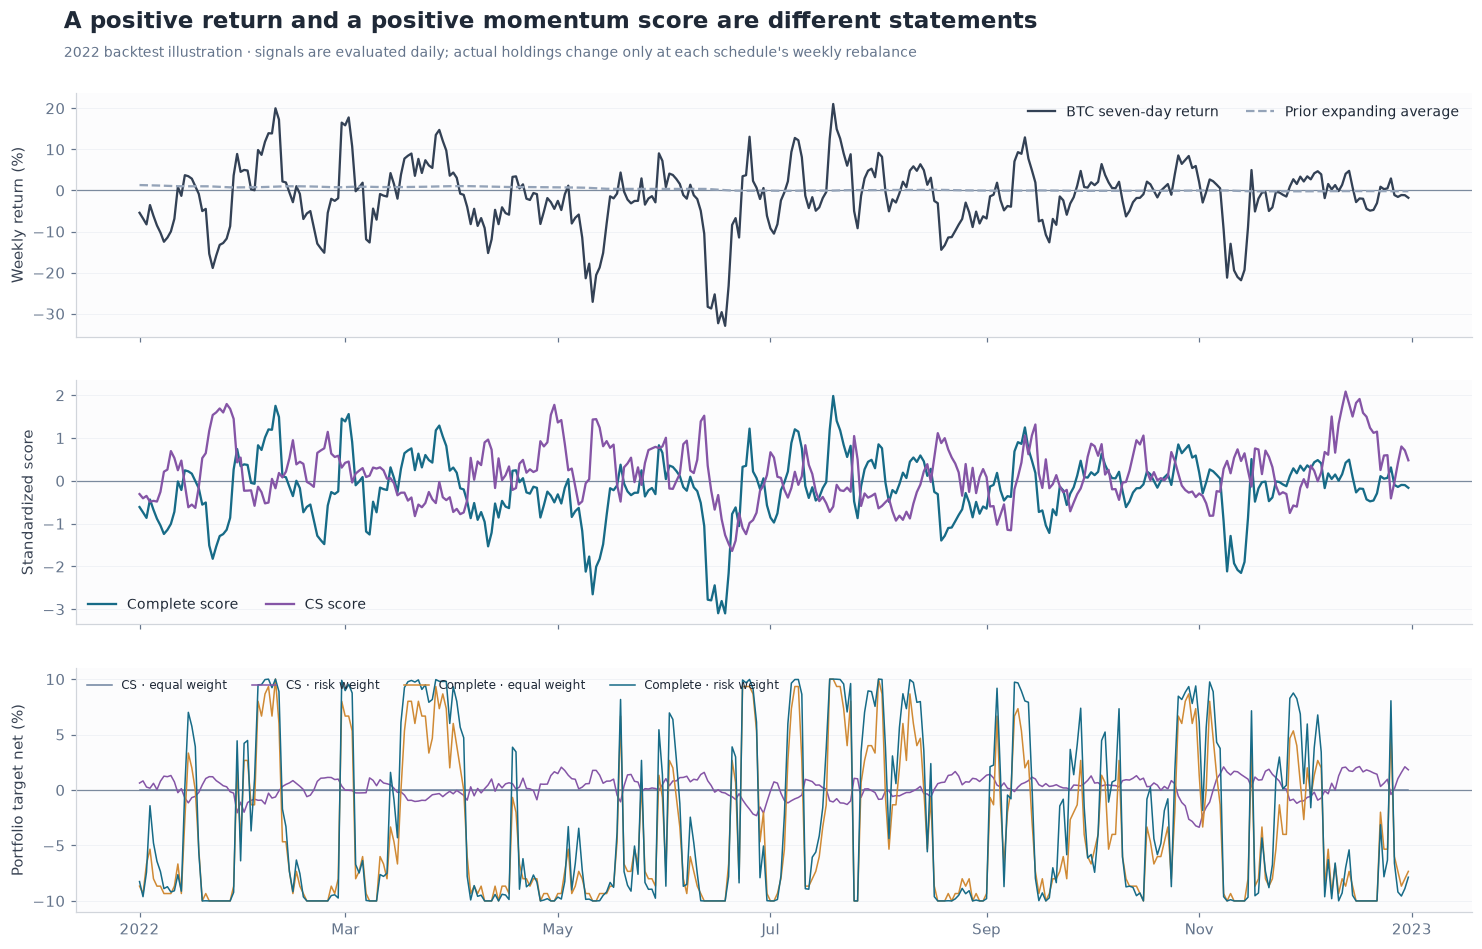

In [6]:
# Fixed backtest window illustrates the difference between raw returns and historical scores.
window=prices.index[(prices.index>="2022-01-01")&(prices.index<="2022-12-31")]
momentum_data=scores[30]
fig,axes=plt.subplots(3,1,figsize=(14,8.8),sharex=True)
axes[0].plot(window,momentum_data["raw"].loc[window,"BTC-USD"]*100,color="#334155",label="BTC seven-day return")
axes[0].plot(window,momentum_data["mean"].loc[window,"BTC-USD"]*100,color="#94a3b8",ls="--",label="Prior expanding average")
axes[0].set_ylabel("Weekly return (%)");axes[0].legend(fontsize=9,ncol=2)
axes[1].plot(window,momentum_data["complete"].loc[window,"BTC-USD"],color="#176b87",label="Complete score")
axes[1].plot(window,momentum_data["cross"].loc[window,"BTC-USD"],color="#8555a6",label="CS score")
axes[1].set_ylabel("Standardized score");axes[1].legend(fontsize=9,ncol=2)
for key in FACTOR_KEYS:
    axes[2].plot(window,100*targets[30][key].loc[window].sum(axis=1),color=COLORS[key],lw=1,label=LABELS[key])
axes[2].set_ylabel("Portfolio target net (%)");axes[2].legend(fontsize=8,ncol=4)
for ax in axes:polish_axis(ax,date_axis=True,zero_line=True)
show_figure(fig,"momentum_walkthrough","A positive return and a positive momentum score are different statements","2022 backtest illustration · signals are evaluated daily; actual holdings change only at each schedule's weekly rebalance")

## 4. Seven weekly accounts and actual traded-notional costs

Monday through Sunday each defines a separate weekly strategy. A formation close determines
the target carried into the next daily return. There are no intervening resizing trades;
asset units remain fixed until the next scheduled close. Weekly targets are computed from
the full historical panel, but each evaluation account starts from cash and follows only its
own scheduled decisions inside that segment.

The net account pays **20 bps per absolute asset dollar bought or sold**, including first
entry and final liquidation. Targets are funded from post-fee equity using a scalar accounting
identity, not portfolio optimization. Short proceeds remain in cash; cash interest, borrow,
funding, and financing returns/costs are assumed zero. Standalone signed factors are therefore
theoretical long–short exposures net of the stated trading fee, not fully costed derivative trades.

Gross return measures the return on the same executed post-trade exposure before the fee
effect; it is not a separately resized frictionless account. Net return reconciles to asset
P&L less fees relative to beginning equity. If entry and liquidation fees on that denominator
are $e_t$ and $x_t$, then $r_t^{net}=(1-e_t)(1+r_t^{gross})-x_t-1$.

In [7]:
def run_account(decision_weights,execute,asset_returns,dates,cost_rate=COST_RATE,keep=False,columns=None):
    rows,assets=asset_returns.shape
    risky=np.zeros(assets);cash=1.
    records=np.zeros((rows,11))
    if keep:
        held=np.zeros((rows,assets));pnl_rows=held.copy();fee_rows=held.copy();trade_rows=held.copy();exit_rows=held.copy()
    for t in range(rows):
        prior_nav=cash+risky.sum()
        previous=risky.copy()
        if execute[t]:
            target=decision_weights[t]
            post_nav=prior_nav
            for _ in range(8):post_nav=prior_nav-cost_rate*np.abs(target*post_nav-previous).sum()
            risky=target*post_nav
            cash=post_nav-risky.sum()
        trade=risky-previous
        entry_fees=cost_rate*np.abs(trade)
        post_nav=cash+risky.sum()
        weight=risky/post_nav
        pnl=risky*asset_returns[t]
        gross=pnl.sum()/post_nav
        risky*=1+asset_returns[t]
        liquidation=np.zeros(assets)
        final_fees=np.zeros(assets)
        if t==rows-1:
            liquidation=-risky.copy();final_fees=cost_rate*np.abs(liquidation)
            cash+=risky.sum()-final_fees.sum();risky[:]=0.
        nav=cash+risky.sum()
        if not np.isfinite(nav) or nav<=0:raise ArithmeticError("Account became insolvent.")
        fees=entry_fees+final_fees
        turnover=(np.abs(trade).sum()+np.abs(liquidation).sum())/prior_nav
        records[t]=[gross,nav/prior_nav-1,fees.sum()/prior_nav,turnover,np.abs(weight).sum(),weight.sum(),
                    entry_fees.sum()/prior_nav,final_fees.sum()/prior_nav,pnl.sum()/prior_nav,nav,bool(execute[t])]
        if keep:
            held[t]=weight;pnl_rows[t]=pnl/prior_nav;fee_rows[t]=fees/prior_nav
            trade_rows[t]=trade/prior_nav;exit_rows[t]=liquidation/prior_nav
    frame=pd.DataFrame(records,index=dates,columns=["gross","net","cost_paid","asset_turnover","gross_exposure",
        "net_exposure","entry_cost","exit_cost","asset_pnl","net_nav","scheduled_rebalance"])
    details=None
    if keep:
        cols=columns if columns is not None else ASSETS
        details={name:pd.DataFrame(x,index=dates,columns=cols) for name,x in [("holding_weights",held),("asset_pnl",pnl_rows),
            ("asset_fees",fee_rows),("formation_trades",trade_rows),("final_liquidation_trades",exit_rows)]}
    return frame,details

def simulate(key,burn,weekday,dates,cost_rate=COST_RATE,keep=False):
    formation=dates-pd.Timedelta(days=1)
    weights=targets[burn][key].loc[formation].to_numpy()
    execute=np.asarray(formation.dayofweek==weekday)
    return run_account(weights,execute,returns.loc[dates].to_numpy(),dates,cost_rate,keep)

def full_week_returns(frame,weekday):
    records=[]
    # Each observation represents one complete holding week in this specific account.
    for start in frame.index:
        formation=start-pd.Timedelta(days=1)
        end=start+pd.Timedelta(days=6)
        if formation.dayofweek!=weekday or end>frame.index[-1]:continue
        block=frame.loc[start:end]
        records.append({"Formation date":formation,"Week end":end,
                        "gross":(1+block.gross).prod()-1,"net":(1+block.net).prod()-1})
    return pd.DataFrame(records).set_index("Week end")

## 5. Backtest selection and validation

The standardized performance tables use daily net returns, the fixed Monday formation schedule,
and 365-day annualization. Total Return and CAGR describe compounded performance; Sharpe and
Sortino use daily returns; and drawdown includes starting capital of one. Alpha, beta, the HAC
p-value, and the Information Ratio use the daily BTC return as a common market benchmark.
Skewness and Pearson kurtosis describe the daily net-return distribution.

The paper-specific comparison still uses complete seven-day holding returns from seven separate
weekly schedules. The median of their net Sharpes selects the construction using backtest dates
alone. Those overlapping schedule observations do not form one investable cumulative wealth curve;
the standardized daily table is therefore based on the predeclared Monday account.


In [8]:
def wealth_and_drawdown(r):
    wealth=(1+r).cumprod()
    return wealth,wealth/wealth.cummax().clip(lower=1)-1

def weekly_statistics(r):
    sd=r.std(ddof=1)
    return {"Complete weeks":len(r),"Annual mean (%)":100*r.mean()*WEEKLY_PERIODS_PER_YEAR,
        "Annual volatility (%)":100*sd*np.sqrt(WEEKLY_PERIODS_PER_YEAR),
        "Sharpe":np.sqrt(WEEKLY_PERIODS_PER_YEAR)*r.mean()/sd if sd>0 else np.nan,
        "Geometric weekly annual rate (%)":100*np.expm1(np.log1p(r).mean()*WEEKLY_PERIODS_PER_YEAR),
        "Skewness":r.skew(),"Pearson kurtosis":r.kurt()+3}

def daily_statistics(frame,basis,benchmark):
    r=frame[basis].dropna();wealth,dd=wealth_and_drawdown(r)
    benchmark=benchmark.reindex(r.index)
    aligned=pd.concat({"strategy":r,"benchmark":benchmark},axis=1, sort=True).dropna()
    fit=sm.OLS(aligned["strategy"].to_numpy(),sm.add_constant(aligned["benchmark"].to_numpy())).fit(
        cov_type="HAC",cov_kwds={"maxlags":min(HAC_LAGS,len(aligned)-1),"use_correction":True},use_t=True)
    residual_sd=np.std(fit.resid,ddof=1)
    sd=r.std(ddof=1);downside=np.sqrt(np.mean(np.minimum(r,0)**2))
    return {"Dates":len(r),"Total return (%)":100*(wealth.iloc[-1]-1),
        "CAGR (%)":100*(wealth.iloc[-1]**(365/len(r))-1),"Volatility (%)":100*sd*np.sqrt(365),
        "Sharpe":np.sqrt(365)*r.mean()/sd if sd>0 else np.nan,
        "Sortino":np.sqrt(365)*r.mean()/downside if downside>0 else np.nan,
        "Max drawdown (%)":100*dd.min(),"Positive days (%)":100*(r>0).mean(),
        "Annual turnover":365*frame.asset_turnover.mean(),
        "Alpha vs BTC (%)":36500*fit.params[0],"Beta vs BTC":fit.params[1],"Alpha HAC p":fit.pvalues[0],
        "Information ratio":fit.params[0]*np.sqrt(365)/residual_sd if residual_sd>1e-12 else np.nan,
        "Skewness":r.skew(),"Pearson kurtosis":r.kurt()+3,
        "Mean gross exposure (%)":100*frame.gross_exposure.mean(),
        "Mean net exposure (%)":100*frame.net_exposure.mean(),
        "Active dates":int((frame.gross_exposure>1e-12).sum())}

CORE_METRICS = ["Total return (%)","CAGR (%)","Volatility (%)","Sharpe","Sortino",
                "Max drawdown (%)","Positive days (%)","Annual turnover"]
INSTITUTIONAL_METRICS = ["Alpha vs BTC (%)","Beta vs BTC","Alpha HAC p",
                         "Information ratio","Skewness","Pearson kurtosis"]

results={};weekly_results={};daily_rows=[];schedule_rows=[]
def evaluate(period,burn):
    dates=PERIOD_DATES[period]
    btc=returns.loc[dates,"BTC-USD"]
    for key in STRATEGIES:
        for weekday in range(7):
            frame,_=simulate(key,burn,weekday,dates)
            result_key=(period,burn,key,weekday)
            results[result_key]=frame
            weeks=full_week_returns(frame,weekday)
            weekly_results[result_key]=weeks
            for basis in ["gross","net"]:
                daily_rows.append({"Period":period,"Burn-in":burn,"Strategy":key,"Weekday":weekday,"Basis":basis,
                                   **daily_statistics(frame,basis,btc)})
                schedule_rows.append({"Period":period,"Burn-in":burn,"Strategy":key,"Weekday":weekday,"Basis":basis,
                                      **weekly_statistics(weeks[basis]),"Annual turnover":365*frame.asset_turnover.mean()})

evaluate("Backtest",30)
initial=pd.DataFrame(schedule_rows)
ranking=initial.query("Basis=='net' and Strategy in @FACTOR_KEYS").groupby("Strategy").agg(
    median_weekly_sharpe=("Sharpe","median"),median_turnover=("Annual turnover","median")).reindex(FACTOR_KEYS)
ranking["Declared order"]=range(4)
ranking=ranking.sort_values(["median_weekly_sharpe","median_turnover","Declared order"],ascending=[False,True,True],kind="stable")
selected_key=ranking.index[0]
frozen_selection={"strategy":selected_key,"criterion":"Median net weekly Sharpe over all 7 schedules, 30-observation burn-in",
    "candidates":FACTOR_KEYS,"representative_weekday":"Monday, fixed","backtest_end":str(PERIOD_DATES["Backtest"][-1].date())}
print("Backtest selection frozen:",LABELS[selected_key])
evaluate("Backtest",90)
# No validation performance was used to choose the construction above.
for burn in BURN_INS:evaluate("Validation",burn)
daily_metrics=pd.DataFrame(daily_rows).set_index(["Period","Burn-in","Strategy","Weekday","Basis"])
schedule_metrics=pd.DataFrame(schedule_rows).set_index(["Period","Burn-in","Strategy","Weekday","Basis"])
pooled_rows=[]
for period in PERIOD_DATES:
    for burn in BURN_INS:
        for key in STRATEGIES:
            pooled=pd.concat([weekly_results[(period,burn,key,d)] for d in range(7)]).sort_index()
            for basis in ["gross","net"]:
                pooled_rows.append({"Period":period,"Burn-in":burn,"Strategy":key,"Basis":basis,**weekly_statistics(pooled[basis])})
pooled_metrics=pd.DataFrame(pooled_rows).set_index(["Period","Burn-in","Strategy","Basis"])
print(f"Evaluated {len(STRATEGIES)} constructions × 7 schedules × 2 burn-ins in each segment.")
ranking_display=ranking[["median_weekly_sharpe","median_turnover"]].copy()
ranking_display["Selected in backtest"]=ranking_display.index==selected_key
display(ranking_display.rename(index=LABELS))


Backtest selection frozen: Complete · risk weight


Evaluated 12 constructions × 7 schedules × 2 burn-ins in each segment.


,median_weekly_sharpe,median_turnover,Selected in backtest
Strategy,,,
Complete · risk weight,0.7686,6.6780,True
Complete · equal weight,0.5663,4.8430,False
CS · equal weight,0.3352,5.4948,False
CS · risk weight,0.1195,7.1858,False


## 6. Momentum constructions and weekly schedule sensitivity

The compact schedule table reports each factor's median, worst, and best net weekly Sharpe across
the seven fixed formation weekdays, plus the number of positive schedules. This retains the
paper-specific sensitivity check without presenting seven nearly identical performance tables.
The weekday heatmap shows the underlying schedule results; no weekday is selected from them.


### Backtest: weekly-schedule robustness

,Median weekday Sharpe,Worst weekday Sharpe,Best weekday Sharpe,Positive schedules
Strategy,,,,
CS · equal weight,0.3352,0.0055,0.4754,7
CS · risk weight,0.1195,-0.2846,0.2908,5
Complete · equal weight,0.5663,-0.1912,0.7624,6
Complete · risk weight,0.7686,-0.0884,0.9401,6


### Validation: weekly-schedule robustness

,Median weekday Sharpe,Worst weekday Sharpe,Best weekday Sharpe,Positive schedules
Strategy,,,,
CS · equal weight,-0.4913,-0.8548,0.0391,1
CS · risk weight,-0.6333,-1.5584,-0.4187,0
Complete · equal weight,-1.0262,-1.6317,0.4622,1
Complete · risk weight,-1.4599,-2.1538,0.2446,1


findfont: Failed to find font weight semibold, now using 700.


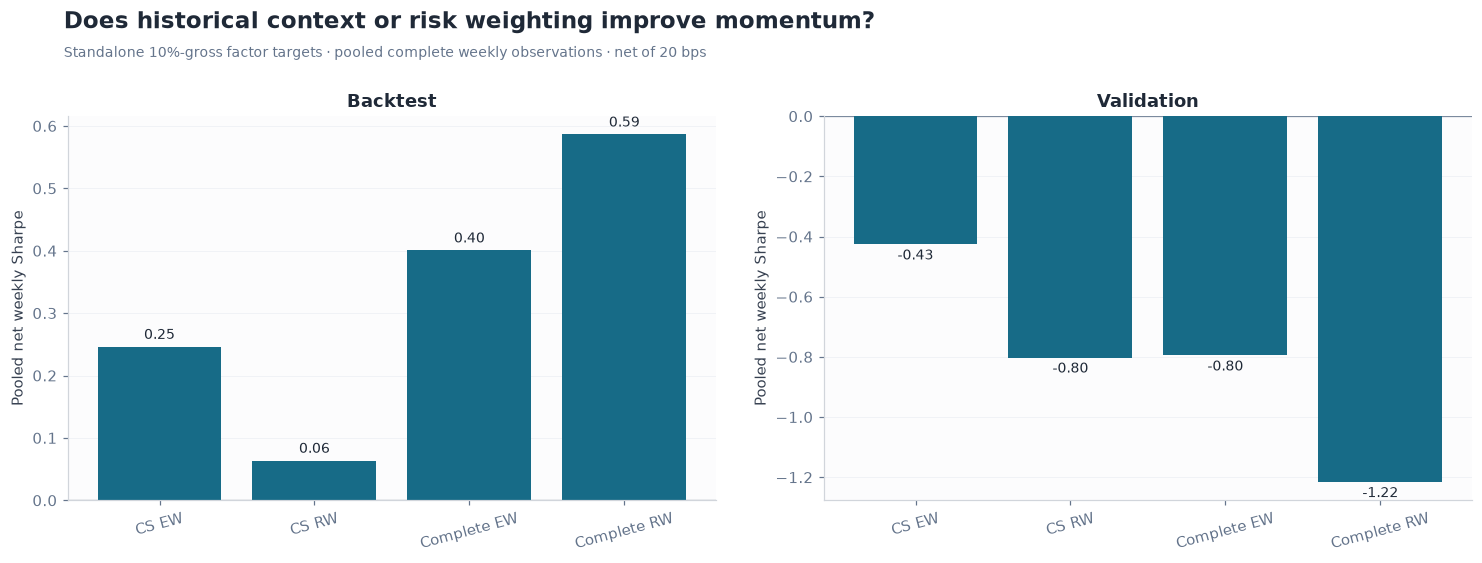

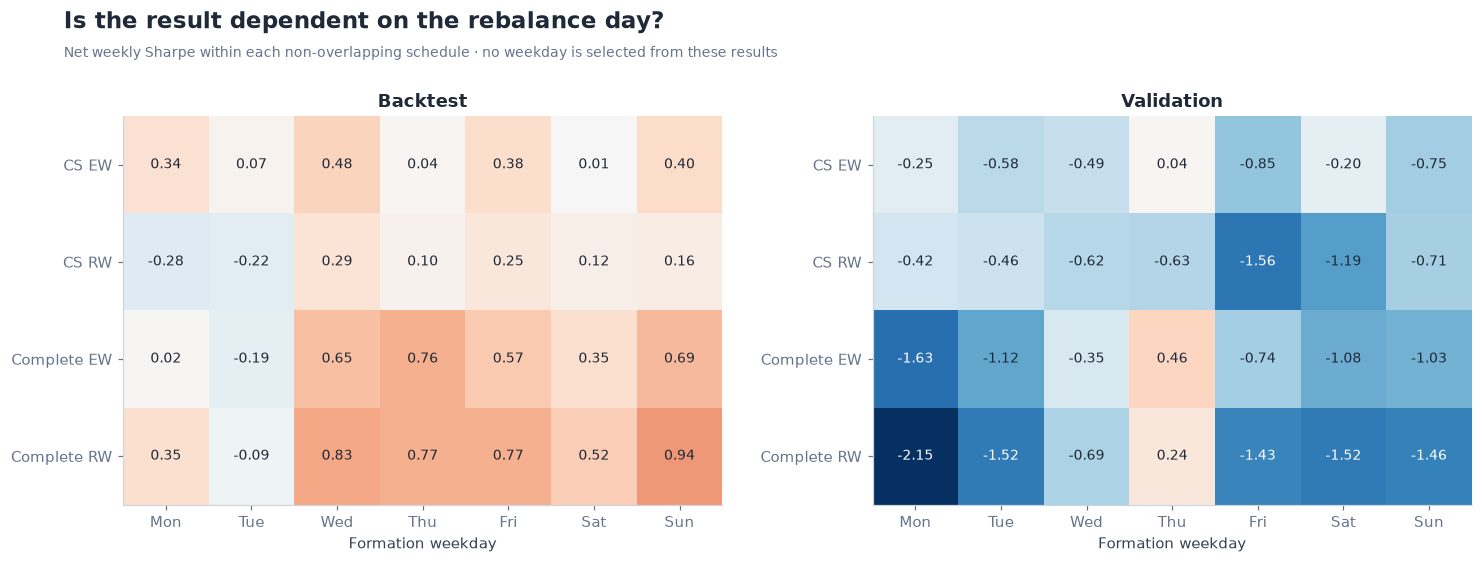

In [9]:
schedule_summary_rows=[]
for period in PERIOD_DATES:
    scheduled=schedule_metrics.xs((period,30,"net"),level=("Period","Burn-in","Basis"))
    for key in FACTOR_KEYS:
        values=scheduled.loc[key,"Sharpe"]
        schedule_summary_rows.append({"Period":period,"Strategy":key,
            "Median weekday Sharpe":values.median(),"Worst weekday Sharpe":values.min(),
            "Best weekday Sharpe":values.max(),"Positive schedules":int((values>0).sum())})
schedule_summary=pd.DataFrame(schedule_summary_rows).set_index(["Period","Strategy"])
for period in PERIOD_DATES:
    display(Markdown(f"### {period}: weekly-schedule robustness"))
    display(schedule_summary.loc[period].rename(index=LABELS))

fig,axes=plt.subplots(1,2,figsize=(14,5.2))
for ax,period in zip(axes,PERIOD_DATES):
    vals=[pooled_metrics.loc[(period,30,k,"net"),"Sharpe"] for k in FACTOR_KEYS]
    bars=ax.bar(np.arange(4),vals,color="#176b87")
    ax.bar_label(bars,fmt="%.2f",padding=3,fontsize=9)
    ax.set_xticks(range(4),["CS EW","CS RW","Complete EW","Complete RW"],rotation=15)
    ax.set_title(period);ax.set_ylabel("Pooled net weekly Sharpe");polish_axis(ax,zero_line=True)
show_figure(fig,"factor_comparison","Does historical context or risk weighting improve momentum?","Standalone 10%-gross factor targets · pooled complete weekly observations · net of 20 bps")

weekday_grids={period:np.array([[schedule_metrics.loc[(period,30,k,d,"net"),"Sharpe"] for d in range(7)] for k in FACTOR_KEYS]) for period in PERIOD_DATES}
bound=max(abs(v).max() for v in weekday_grids.values())
fig,axes=plt.subplots(1,2,figsize=(14,5.2))
for ax,period in zip(axes,PERIOD_DATES):
    vals=weekday_grids[period];ax.imshow(vals,cmap="RdBu_r",vmin=-bound,vmax=bound,aspect="auto")
    for (row,column),value in np.ndenumerate(vals):
        ax.text(column,row,f"{value:.2f}",ha="center",va="center",fontsize=9,
                color="white" if abs(value)>.6*bound else "#1f2937")
    ax.set_xticks(range(7),WEEKDAYS);ax.set_yticks(range(4),["CS EW","CS RW","Complete EW","Complete RW"])
    ax.set_title(period);ax.set_xlabel("Formation weekday")
show_figure(fig,"weekly_schedule_sensitivity","Is the result dependent on the rebalance day?","Net weekly Sharpe within each non-overlapping schedule · no weekday is selected from these results")


## 7. Alpha relative to all three paper benchmarks

For each factor and momentum-only overlay, pooled weekly returns are separately regressed on the
equal-, capitalization-, and risk-weighted benchmark returns. Newey–West/HAC retains 20 lags for
the overlapping weekly sample. The compact output keeps annual alpha, beta, the raw HAC p-value,
and the residual-risk Information Ratio; confidence bounds and multiple-testing flags are omitted.


### Backtest: net weekly alpha, 30-observation burn-in

Annual alpha (%)    Beta  HAC p  Information ratio
Strategy       Benchmark                                                    
MOM_CPL_EW     BM_CW                3.7188 -0.3712 0.1140             0.6847
               BM_EW                3.8417 -0.2402 0.0902             0.6890
               BM_RW                3.7862 -0.2415 0.0946             0.6772
MOM_CPL_RW     BM_CW                4.7639 -0.2151 0.0904             0.7162
               BM_EW                4.4730 -0.0804 0.0876             0.6625
               BM_RW                4.4417 -0.0788 0.0892             0.6575
MOM_CS_EW      BM_CW                0.5148 -0.0077 0.4861             0.2604
               BM_EW                0.3365  0.0243 0.5969             0.1710
               BM_RW                0.3732  0.0192 0.5682             0.1893
MOM_CS_RW      BM_CW                0.2643 -0.0142 0.8358             0.0790
               BM_EW                0.1010  0.0181 0.9316             0.0302
               BM_RW                0.1390  0.0125 0.9066             0.0416
OVERLAY_CPL_EW BM_CW                5.8148  0.7850 0.0736             0.8758
               BM_EW                4.0015  0.7599 0.0776             0.7178
               BM_RW                4.0530  0.7852 0.0738             0.7299
OVERLAY_CPL_RW BM_CW                6.4314  1.0386 0.0865             0.8354
               BM_EW                4.1743  0.9823 0.0869             0.6651
               BM_RW                4.2157  1.0194 0.0805             0.6797
OVERLAY_CS_EW  BM_CW                2.5772  1.1486 0.2754             0.5769
               BM_EW                0.4626  1.0244 0.4672             0.2351
               BM_RW                0.6064  1.0461 0.4224             0.2711
OVERLAY_CS_RW  BM_CW                2.6114  1.2334 0.3151             0.5203
               BM_EW                0.4681  1.0794 0.6727             0.1521
               BM_RW                0.5780  1.1093 0.6014             0.1846

### Validation: net weekly alpha, 30-observation burn-in

Annual alpha (%)    Beta  HAC p  Information ratio
Strategy       Benchmark                                                    
MOM_CPL_EW     BM_CW               -4.1551 -0.4899 0.0818            -1.0121
               BM_EW               -5.0821 -0.3344 0.0529            -1.2112
               BM_RW               -4.9685 -0.3522 0.0557            -1.1885
MOM_CPL_RW     BM_CW               -6.3729 -0.4375 0.0151            -1.4163
               BM_EW               -7.1859 -0.2950 0.0116            -1.5710
               BM_RW               -7.0867 -0.3110 0.0119            -1.5532
MOM_CS_EW      BM_CW               -0.4675 -0.0275 0.4291            -0.4538
               BM_EW               -0.5283 -0.0209 0.4042            -0.5131
               BM_RW               -0.5209 -0.0219 0.4063            -0.5059
MOM_CS_RW      BM_CW               -1.4678 -0.0422 0.1324            -0.8286
               BM_EW               -1.4866 -0.0140 0.1456            -0.8353
               BM_RW               -1.4838 -0.0152 0.1439            -0.8338
OVERLAY_CPL_EW BM_CW               -7.0120  0.7246 0.0254            -1.4535
               BM_EW               -4.9384  0.6655 0.0597            -1.1775
               BM_RW               -5.2237  0.6844 0.0478            -1.2358
OVERLAY_CPL_RW BM_CW               -8.2388  0.9219 0.0090            -1.6994
               BM_EW               -5.7553  0.8091 0.0232            -1.4122
               BM_RW               -6.0912  0.8351 0.0167            -1.4842
OVERLAY_CS_EW  BM_CW               -3.3565  1.1868 0.0852            -1.2019
               BM_EW               -0.4177  0.9787 0.5091            -0.4059
               BM_RW               -0.8090  1.0144 0.2159            -0.7677
OVERLAY_CS_RW  BM_CW               -3.8229  1.3032 0.0767            -1.1432
               BM_EW               -0.5838  1.0776 0.5327            -0.3474
               BM_RW               -1.0118  1.1178 0.2762            -0.6019

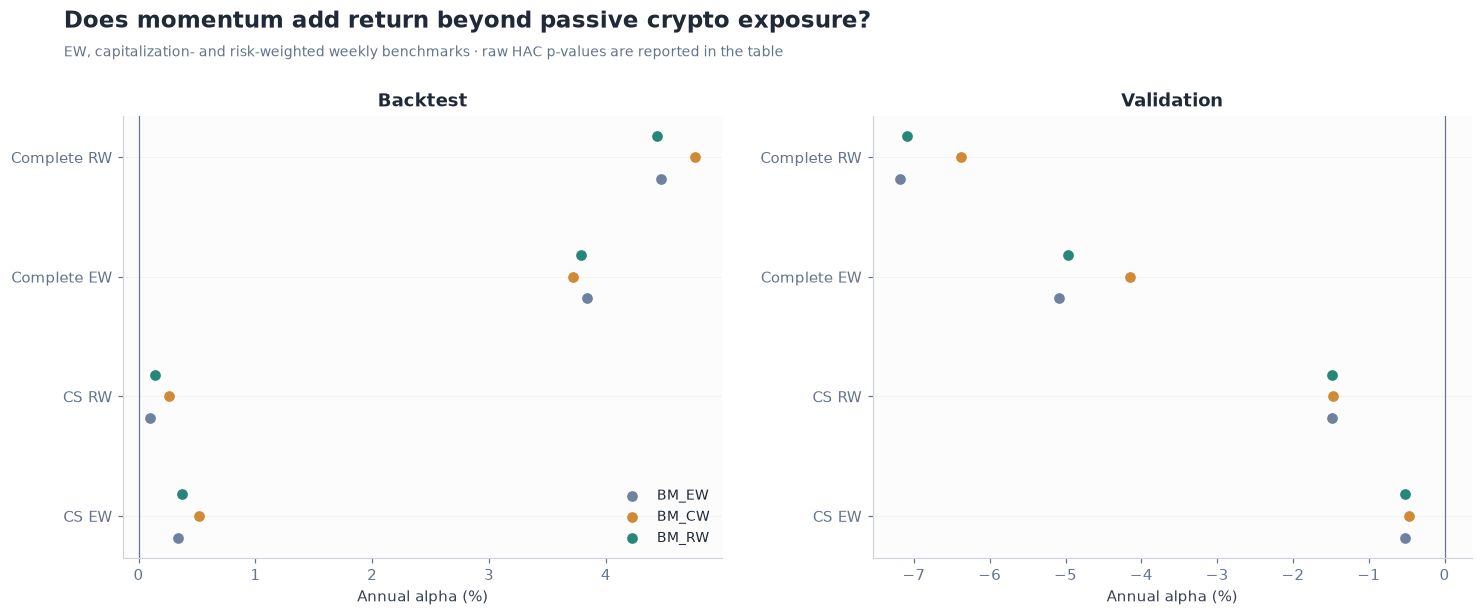

In [10]:
def pooled_weekly(period, burn, key):
    return pd.concat([weekly_results[(period,burn,key,d)] for d in range(7)]).sort_index()

alpha_rows=[]
for period in PERIOD_DATES:
    for burn in BURN_INS:
        for basis in ["gross","net"]:
            for key in FACTOR_KEYS+OVERLAY_KEYS:
                strategy_returns=pooled_weekly(period,burn,key)[basis]
                for benchmark_key in PRIMARY_BENCHMARKS:
                    benchmark=pooled_weekly(period,burn,benchmark_key)[basis].reindex(strategy_returns.index)
                    fit=sm.OLS(strategy_returns.to_numpy(),sm.add_constant(benchmark.to_numpy())).fit(
                        cov_type="HAC",cov_kwds={"maxlags":HAC_LAGS,"use_correction":True},use_t=True)
                    residual_sd=np.std(fit.resid,ddof=1)
                    alpha_rows.append({"Period":period,"Burn-in":burn,"Basis":basis,"Strategy":key,
                        "Benchmark":benchmark_key,"Annual alpha (%)":fit.params[0]*100*WEEKLY_PERIODS_PER_YEAR,
                        "Beta":fit.params[1],"HAC p":fit.pvalues[0],
                        "Information ratio":fit.params[0]*np.sqrt(WEEKLY_PERIODS_PER_YEAR)/residual_sd if residual_sd>1e-12 else np.nan})
alpha_table=pd.DataFrame(alpha_rows).set_index(["Period","Burn-in","Basis","Strategy","Benchmark"]).sort_index()
for period in PERIOD_DATES:
    display(Markdown(f"### {period}: net weekly alpha, 30-observation burn-in"))
    display(alpha_table.loc[(period,30,"net")])

fig,axes=plt.subplots(1,2,figsize=(14,5.7))
benchmark_style=[(-.18,"BM_EW","#6d829f"),(0.,"BM_CW","#d08a35"),(.18,"BM_RW","#268779")]
for ax,period in zip(axes,PERIOD_DATES):
    for offset,benchmark_key,color in benchmark_style:
        rows=alpha_table.loc[(period,30,"net")].xs(benchmark_key,level="Benchmark").reindex(FACTOR_KEYS)
        ax.scatter(rows["Annual alpha (%)"],np.arange(4)+offset,color=color,label=benchmark_key)
    ax.axvline(0,color="#64748b",lw=.8);ax.set_yticks(range(4),["CS EW","CS RW","Complete EW","Complete RW"])
    ax.set_title(period);ax.set_xlabel("Annual alpha (%)");polish_axis(ax)
axes[0].legend(fontsize=9)
show_figure(fig,"momentum_alpha","Does momentum add return beyond passive crypto exposure?","EW, capitalization- and risk-weighted weekly benchmarks · raw HAC p-values are reported in the table")


## 8. Standardized daily performance and representative accounts

The standardized tables use the fixed Monday account, daily net returns, and consistent
column definitions throughout this notebook. The first table contains return and risk measures;
the second retains alpha, beta, HAC significance, Information Ratio, skewness, and kurtosis.
The plots focus on the paper anchor, backtest selection, matching overlay, and benchmark.


### Backtest: standardized net performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover
Strategy,,,,,,,,
CS · equal weight,2.8222,0.6982,1.9176,0.3724,0.5867,-3.7555,49.0411,5.5114
CS · risk weight,-3.7734,-0.9570,3.1023,-0.2945,-0.4414,-6.9702,43.6986,7.2039
Complete · equal weight,-0.1380,-0.0345,5.8960,0.0236,0.0345,-10.8067,48.0137,5.1711
Complete · risk weight,9.1569,2.2146,6.6408,0.3630,0.5485,-11.0480,47.6027,6.8533
Momentum overlay · CS · equal weight,33.1886,7.4278,8.1676,0.9182,1.2921,-11.8228,52.1918,5.3938
Momentum overlay · CS · risk weight,27.7890,6.3221,8.9623,0.7289,1.0236,-13.8661,50.9589,6.0225
Momentum overlay · Complete · equal weight,30.7842,6.9397,7.2195,0.9655,1.4388,-10.4269,44.4521,4.8382
Momentum overlay · Complete · risk weight,40.5683,8.8859,9.0850,0.9825,1.4735,-13.1974,51.5753,5.6687


**Distribution and benchmark diagnostics**

,Alpha vs BTC (%),Beta vs BTC,Alpha HAC p,Information ratio,Skewness,Pearson kurtosis
Strategy,,,,,,
CS · equal weight,0.7895,-0.0016,0.4242,0.4123,1.9826,28.5573
CS · risk weight,-0.9365,0.0005,0.5155,-0.3019,0.7247,11.4245
Complete · equal weight,2.0889,-0.0406,0.4659,0.3916,0.7068,12.5048
Complete · risk weight,3.7346,-0.0276,0.2727,0.5819,0.7362,10.3422
Momentum overlay · CS · equal weight,2.7806,0.0982,0.4103,0.5095,-0.5919,9.1388
Momentum overlay · CS · risk weight,1.3136,0.1086,0.6971,0.2216,-0.4994,7.2930
Momentum overlay · Complete · equal weight,4.1309,0.0591,0.2757,0.6636,0.0641,11.1861
Momentum overlay · Complete · risk weight,5.0030,0.0816,0.2725,0.6626,0.2529,11.1665


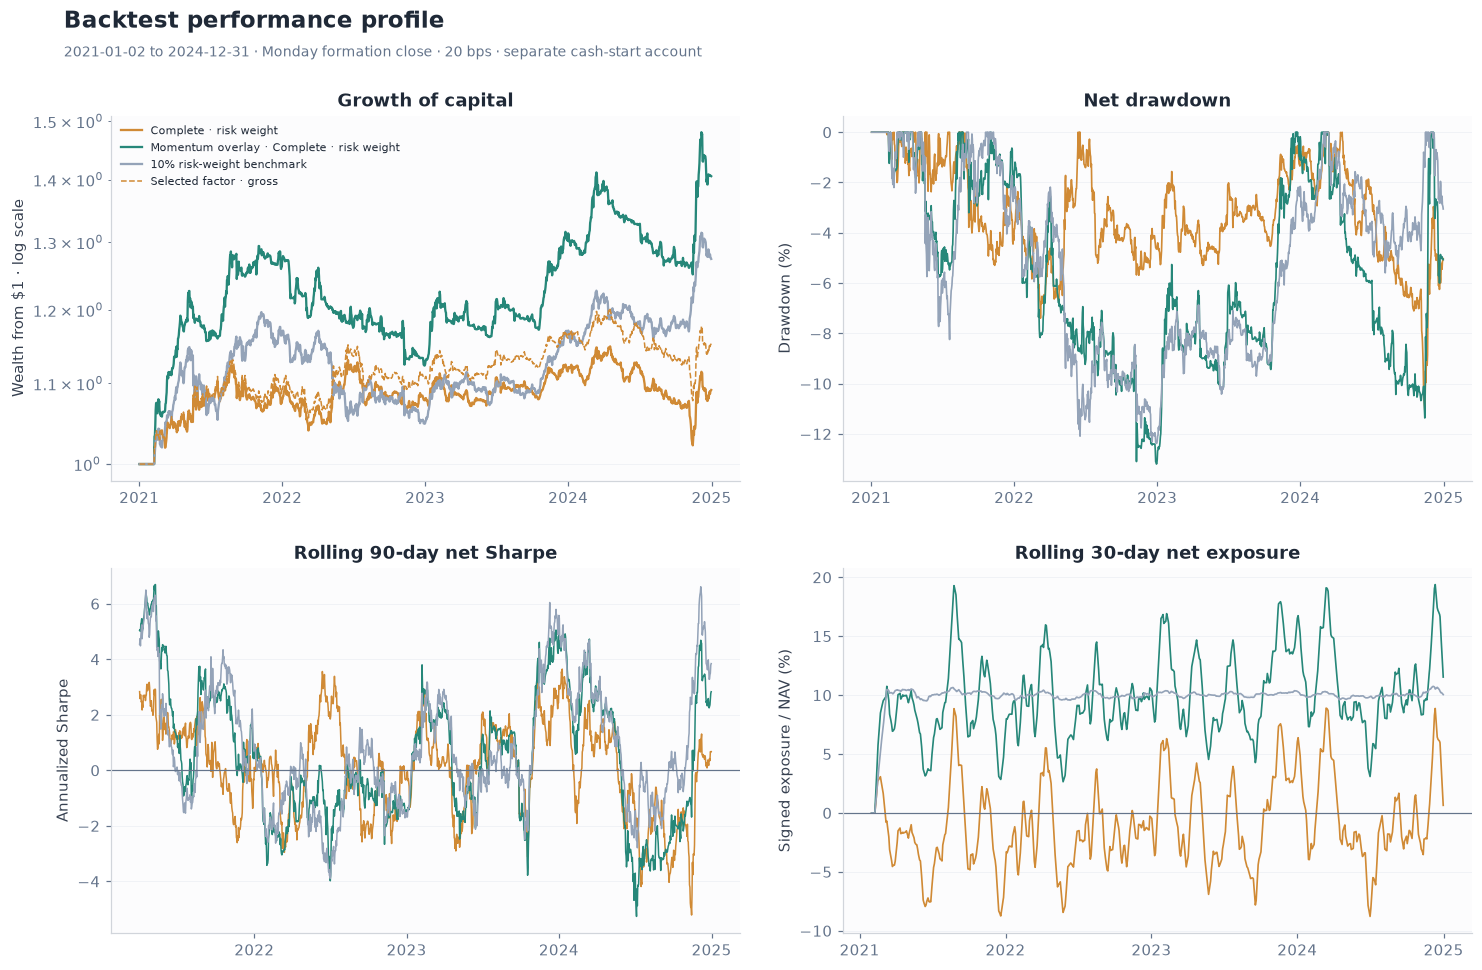

### Validation: standardized net performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover
Strategy,,,,,,,,
CS · equal weight,-0.6364,-0.3721,1.2017,-0.3042,-0.4147,-1.5445,49.4400,5.2773
CS · risk weight,-1.2816,-0.7505,1.9811,-0.3704,-0.5304,-2.5668,47.8400,7.2362
Complete · equal weight,-12.6425,-7.5899,5.4275,-1.4271,-1.8545,-13.3594,47.6800,5.6780
Complete · risk weight,-17.0812,-10.3617,5.7847,-1.8618,-2.4079,-17.4355,45.1200,7.3792
Momentum overlay · CS · equal weight,-7.6261,-4.5269,6.4550,-0.6854,-0.9300,-10.2046,48.6400,5.1616
Momentum overlay · CS · risk weight,-7.1940,-4.2664,7.2322,-0.5667,-0.7746,-10.9359,50.2400,5.9809
Momentum overlay · Complete · equal weight,-18.5982,-11.3231,6.2139,-1.9023,-2.2309,-18.9126,44.1600,5.3998
Momentum overlay · Complete · risk weight,-20.1754,-12.3306,6.7828,-1.9058,-2.2816,-20.8465,49.1200,6.0758


**Distribution and benchmark diagnostics**

,Alpha vs BTC (%),Beta vs BTC,Alpha HAC p,Information ratio,Skewness,Pearson kurtosis
Strategy,,,,,,
CS · equal weight,-0.3794,-0.0062,0.6811,-0.3242,-0.7585,17.1978
CS · risk weight,-0.7470,-0.0060,0.5855,-0.3804,0.0003,12.4578
Complete · equal weight,-7.8730,-0.0577,0.0258,-1.6377,-0.4404,10.6195
Complete · risk weight,-10.8915,-0.0549,0.0042,-2.0690,-0.3353,9.2410
Momentum overlay · CS · equal weight,-4.1560,0.1212,0.1396,-1.1247,-0.2538,6.7268
Momentum overlay · CS · risk weight,-3.8038,0.1332,0.2227,-0.8850,-0.2364,6.4446
Momentum overlay · Complete · equal weight,-11.6663,0.0699,0.0045,-2.1554,-3.1146,36.8812
Momentum overlay · Complete · risk weight,-12.7348,0.0866,0.0018,-2.2618,-2.1999,24.5289


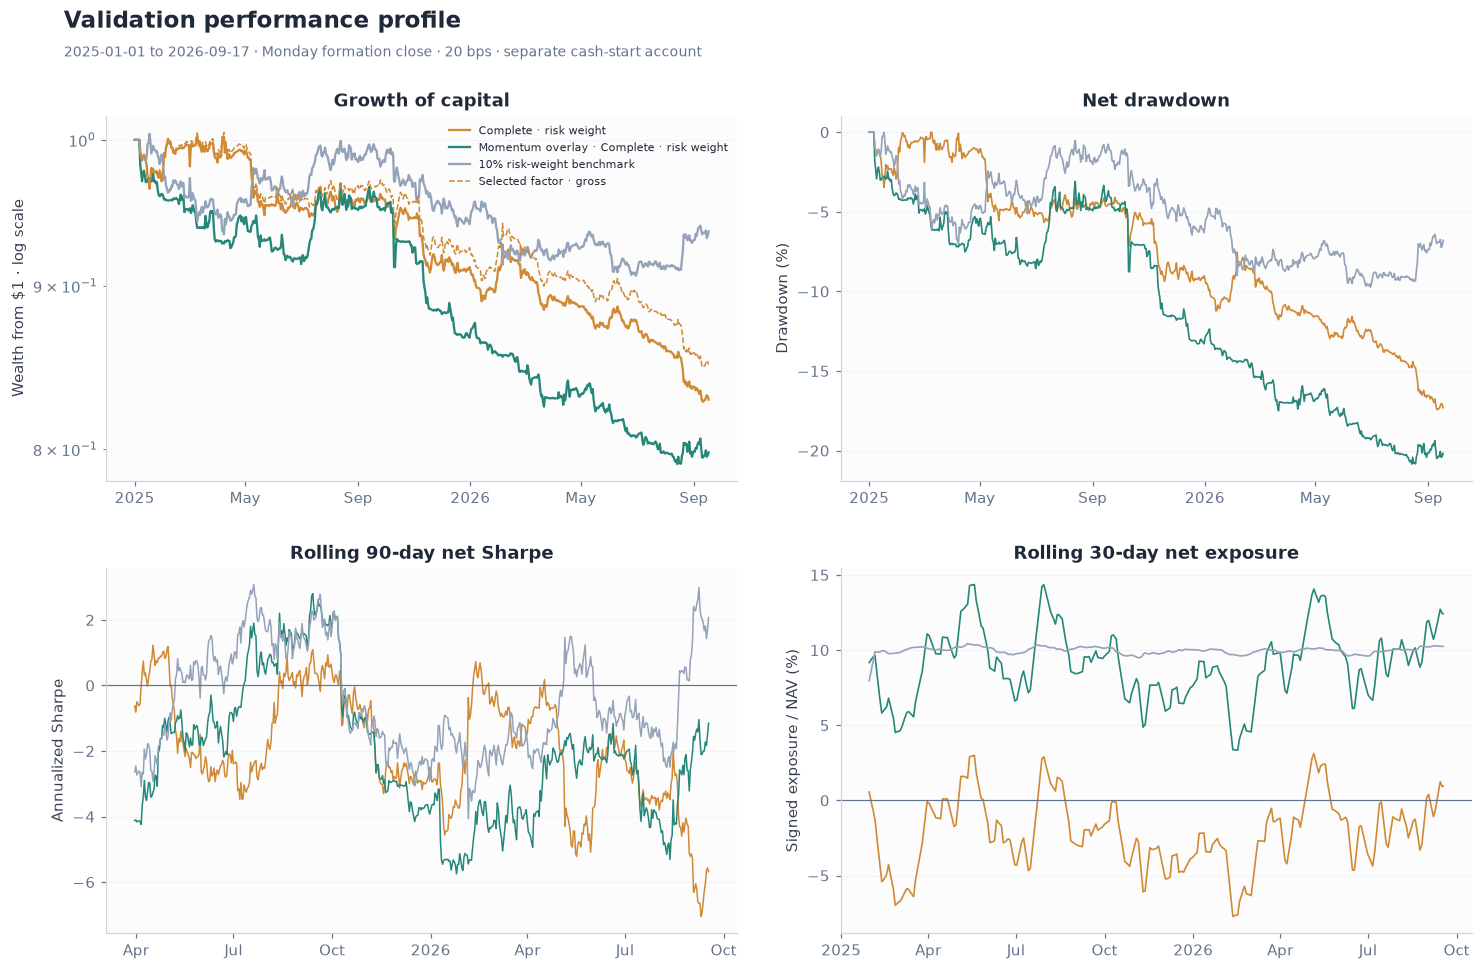

In [11]:
focus_factors=list(dict.fromkeys([ANCHOR_KEY,selected_key]))
selected_overlay=selected_key.replace("MOM_","OVERLAY_")
selected_benchmark="BM_"+selected_key.rsplit("_",1)[-1]
focus_keys=list(dict.fromkeys(focus_factors+[selected_overlay,selected_benchmark]))
REPORT_KEYS=FACTOR_KEYS+OVERLAY_KEYS
details={}
for period,dates in PERIOD_DATES.items():
    for key in focus_keys:
        rerun,detail=simulate(key,30,REPRESENTATIVE_WEEKDAY,dates,keep=True)
        if not np.allclose(rerun.net,results[(period,30,key,REPRESENTATIVE_WEEKDAY)].net):raise AssertionError("Detail rerun differs")
        details[(period,key)]=detail

    standardized=daily_metrics.xs((period,30,REPRESENTATIVE_WEEKDAY,"net"),
        level=("Period","Burn-in","Weekday","Basis")).reindex(REPORT_KEYS)
    display(Markdown(f"### {period}: standardized net performance"))
    display(standardized[CORE_METRICS].rename(index=LABELS))
    display(Markdown("**Distribution and benchmark diagnostics**"))
    display(standardized[INSTITUTIONAL_METRICS].rename(index=LABELS))

    fig,axes=plt.subplots(2,2,figsize=(14,9))
    colors={ANCHOR_KEY:"#176b87",selected_key:"#d08a35",selected_overlay:"#268779",selected_benchmark:"#94a3b8"}
    for key in focus_keys:
        frame=results[(period,30,key,REPRESENTATIVE_WEEKDAY)]
        wealth,dd=wealth_and_drawdown(frame.net);color=colors[key]
        axes[0,0].plot(dates,wealth,color=color,lw=1.5,label=LABELS[key])
        axes[0,1].plot(dates,dd*100,color=color,lw=1.1)
        rolling=frame.net.rolling(90,min_periods=90)
        axes[1,0].plot(dates,np.sqrt(365)*rolling.mean()/rolling.std(),color=color,lw=1)
        axes[1,1].plot(dates,100*frame.net_exposure.rolling(30,min_periods=30).mean(),color=color,lw=1.1)
    axes[0,0].plot(dates,(1+results[(period,30,selected_key,REPRESENTATIVE_WEEKDAY)].gross).cumprod(),
                   color=colors[selected_key],ls="--",lw=1,label="Selected factor · gross")
    axes[0,0].set_yscale("log");axes[0,0].legend(fontsize=7,ncol=1)
    for ax,title,ylabel in [(axes[0,0],"Growth of capital","Wealth from $1 · log scale"),
        (axes[0,1],"Net drawdown","Drawdown (%)"),(axes[1,0],"Rolling 90-day net Sharpe","Annualized Sharpe"),
        (axes[1,1],"Rolling 30-day net exposure","Signed exposure / NAV (%)")]:
        ax.set_title(title);ax.set_ylabel(ylabel);polish_axis(ax,date_axis=True)
    axes[1,0].axhline(0,color="#64748b",lw=.8);axes[1,1].axhline(0,color="#64748b",lw=.8)
    show_figure(fig,f"{period.lower()}_performance",f"{period} performance profile",f"{dates[0].date()} to {dates[-1].date()} · Monday formation close · 20 bps · separate cash-start account")


### Backtest-to-validation comparison

Each strategy is evaluated under all seven fixed weekly rebalance schedules. The table and chart
show the ten strategy–weekday pairs with the highest **backtest** net weekly Sharpe, then carry
those exact pairs unchanged into validation. Validation results do not determine which rows are
shown. `Selected construction in backtest` identifies the construction chosen from its median
Sharpe across all seven schedules; it does not mean that a particular weekday was selected.


Backtest Sharpe  \
Strategy                                   Rebalance day                    
Momentum overlay · Complete · equal weight Wed                     1.3331   
                                           Thu                     1.2965   
Momentum overlay · Complete · risk weight  Sun                     1.2459   
Momentum overlay · Complete · equal weight Sun                     1.2307   
Momentum overlay · Complete · risk weight  Wed                     1.2306   
                                           Thu                     1.1505   
Momentum overlay · Complete · equal weight Fri                     1.0475   
Momentum overlay · Complete · risk weight  Fri                     1.0457   
Complete · risk weight                     Sun                     0.9401   
Momentum overlay · Complete · risk weight  Mon                     0.9342   

                                                          Validation Sharpe  \
Strategy                                   Rebalance day                      
Momentum overlay · Complete · equal weight Wed                      -1.0280   
                                           Thu                      -0.3005   
Momentum overlay · Complete · risk weight  Sun                      -1.7756   
Momentum overlay · Complete · equal weight Sun                      -1.7031   
Momentum overlay · Complete · risk weight  Wed                      -1.1224   
                                           Thu                      -0.4280   
Momentum overlay · Complete · equal weight Fri                      -1.2940   
Momentum overlay · Complete · risk weight  Fri                      -1.4950   
Complete · risk weight                     Sun                      -1.4599   
Momentum overlay · Complete · risk weight  Mon                      -1.9596   

                                                          Sharpe change  \
Strategy                                   Rebalance day                  
Momentum overlay · Complete · equal weight Wed                  -2.3611   
                                           Thu                  -1.5970   
Momentum overlay · Complete · risk weight  Sun                  -3.0215   
Momentum overlay · Complete · equal weight Sun                  -2.9338   
Momentum overlay · Complete · risk weight  Wed                  -2.3530   
                                           Thu                  -1.5785   
Momentum overlay · Complete · equal weight Fri                  -2.3415   
Momentum overlay · Complete · risk weight  Fri                  -2.5407   
Complete · risk weight                     Sun                  -2.4000   
Momentum overlay · Complete · risk weight  Mon                  -2.8938   

                                                          Selected construction in backtest  
Strategy                                   Rebalance day                                     
Momentum overlay · Complete · equal weight Wed                                        False  
                                           Thu                                        False  
Momentum overlay · Complete · risk weight  Sun                                        False  
Momentum overlay · Complete · equal weight Sun                                        False  
Momentum overlay · Complete · risk weight  Wed                                        False  
                                           Thu                                        False  
Momentum overlay · Complete · equal weight Fri                                        False  
Momentum overlay · Complete · risk weight  Fri                                        False  
Complete · risk weight                     Sun                                         True  
Momentum overlay · Complete · risk weight  Mon                                        False

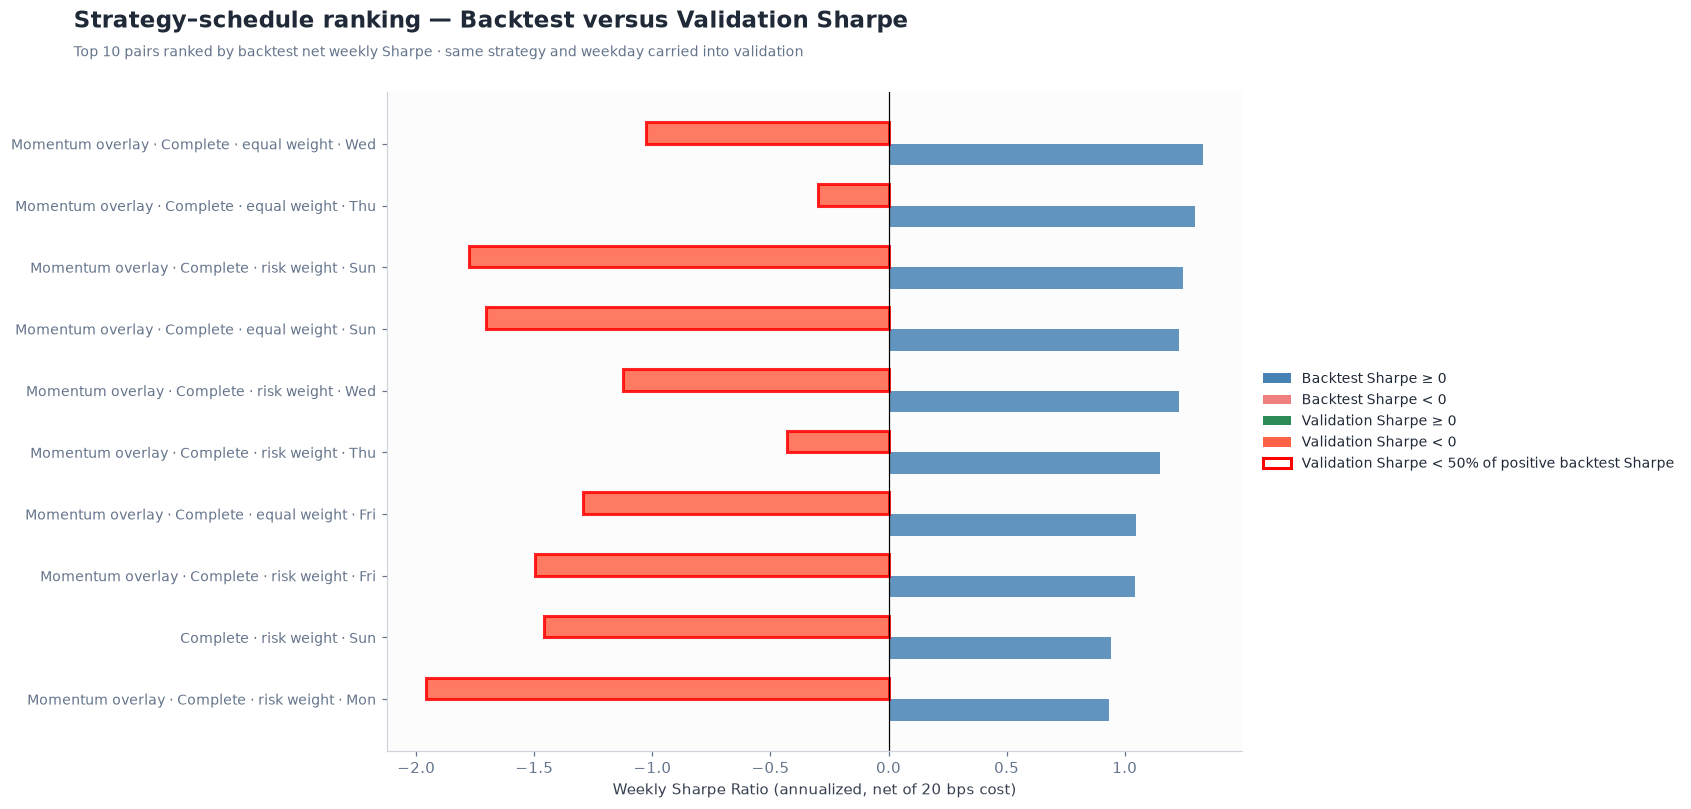

In [12]:
generalization_rows=[]
for key in REPORT_KEYS:
    for weekday,weekday_name in enumerate(WEEKDAYS):
        backtest_sharpe=schedule_metrics.loc[("Backtest",30,key,weekday,"net"),"Sharpe"]
        validation_sharpe=schedule_metrics.loc[("Validation",30,key,weekday,"net"),"Sharpe"]
        generalization_rows.append({"Strategy":LABELS[key],"Rebalance day":weekday_name,
            "Backtest Sharpe":backtest_sharpe,"Validation Sharpe":validation_sharpe,
            "Sharpe change":validation_sharpe-backtest_sharpe,
            "Selected construction in backtest":key==selected_key})
generalization_table=pd.DataFrame(generalization_rows).set_index(["Strategy","Rebalance day"])
# Rank only on backtest performance; stable sorting preserves declared order for exact ties.
comparison=(generalization_table
            .sort_values("Backtest Sharpe",ascending=False,kind="stable")
            .head(10))
display(comparison)

# Horizontal comparison uses the same ordering and rows as the table above.
y=np.arange(len(comparison))
bar_height=0.35
fig,ax=plt.subplots(figsize=(16,max(7,0.55*len(comparison)+2)))
backtest_colors=["steelblue" if value>=0 else "lightcoral" for value in comparison["Backtest Sharpe"]]
validation_colors=["seagreen" if value>=0 else "tomato" for value in comparison["Validation Sharpe"]]
ax.barh(y+bar_height/2,comparison["Backtest Sharpe"].to_numpy(),bar_height,
        color=backtest_colors,label="Backtest (2021–2024)",alpha=0.85)
validation_bars=ax.barh(y-bar_height/2,comparison["Validation Sharpe"].to_numpy(),bar_height,
                        color=validation_colors,label="Validation (2025–2026)",alpha=0.85)

# Red borders flag a validation Sharpe below half of a positive backtest Sharpe.
for bar,backtest_value,validation_value in zip(
        validation_bars,comparison["Backtest Sharpe"],comparison["Validation Sharpe"]):
    if backtest_value>0 and validation_value<0.5*backtest_value:
        bar.set_edgecolor("red")
        bar.set_linewidth(2.0)

ax.set_yticks(y)
comparison_labels=[f"{strategy} · {weekday}" for strategy,weekday in comparison.index]
ax.set_yticklabels(comparison_labels,fontsize=9)
ax.invert_yaxis()
ax.axvline(0,color="black",linewidth=0.8)
ax.set_xlabel("Weekly Sharpe Ratio (annualized, net of 20 bps cost)")
from matplotlib.patches import Patch
legend_handles=[
    Patch(facecolor="steelblue",label="Backtest Sharpe ≥ 0"),
    Patch(facecolor="lightcoral",label="Backtest Sharpe < 0"),
    Patch(facecolor="seagreen",label="Validation Sharpe ≥ 0"),
    Patch(facecolor="tomato",label="Validation Sharpe < 0"),
    Patch(facecolor="none",edgecolor="red",linewidth=2,
          label="Validation Sharpe < 50% of positive backtest Sharpe"),
]
ax.legend(handles=legend_handles,loc="center left",bbox_to_anchor=(1.01,0.5),fontsize=9)
show_figure(fig,"strategy_train_validation_sharpe",
            "Strategy–schedule ranking — Backtest versus Validation Sharpe",
            "Top 10 pairs ranked by backtest net weekly Sharpe · same strategy and weekday carried into validation")


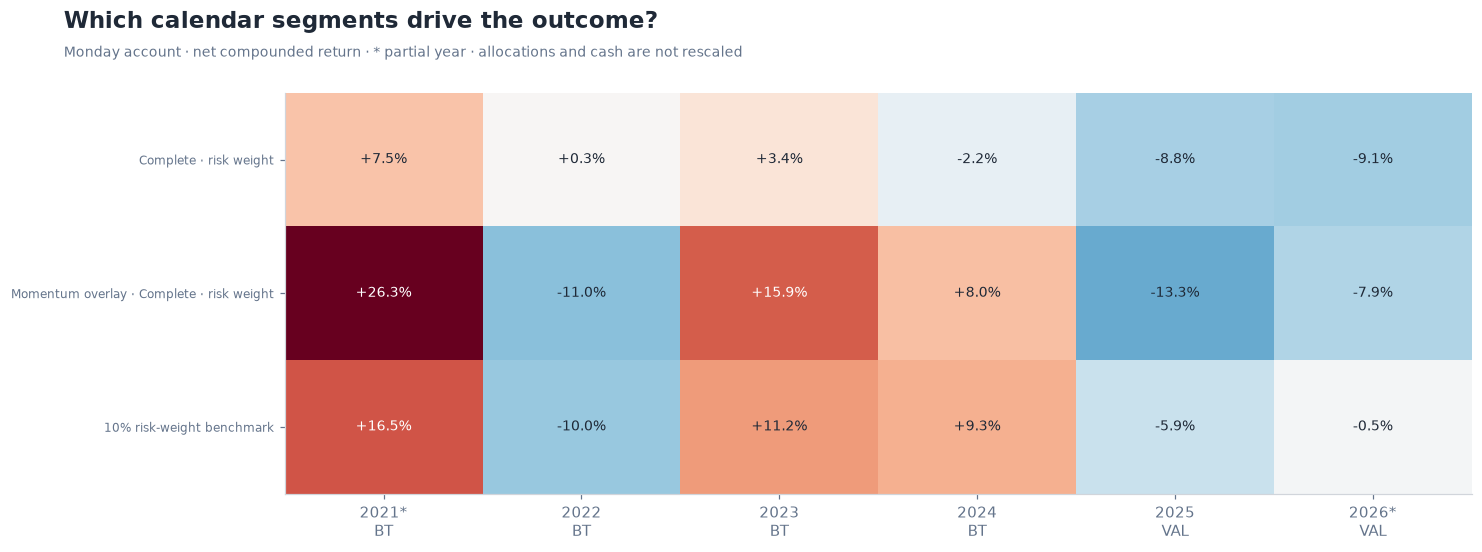

In [13]:
calendar_rows=[]
for period in PERIOD_DATES:
    for key in focus_keys:
        frame=results[(period,30,key,REPRESENTATIVE_WEEKDAY)]
        for year,block in frame.groupby(frame.index.year):
            calendar_rows.append({"Period":period,"Year":year,"Strategy":key,
                "Dates":len(block),"Net return (%)":100*((1+block.net).prod()-1)})
calendar_returns=pd.DataFrame(calendar_rows).set_index(["Period","Year","Strategy"]).sort_index()
wide=calendar_returns["Net return (%)"].unstack("Strategy").reindex(columns=focus_keys)
values=wide.to_numpy().T;bound=max(abs(values).max(),1.)
fig,ax=plt.subplots(figsize=(14,5.1))
ax.imshow(values,cmap="RdBu_r",vmin=-bound,vmax=bound,aspect="auto")
for (row,column),value in np.ndenumerate(values):
    ax.text(column,row,f"{value:+.1f}%",ha="center",va="center",fontsize=9,
            color="white" if abs(value)>.6*bound else "#1f2937")
labels=[]
for period,year in wide.index:
    count=calendar_returns.loc[(period,year)].iloc[0]["Dates"]
    expected=366 if pd.Timestamp(year,12,31).is_leap_year else 365
    labels.append(f"{year}{'*' if count!=expected else ''}\n{'BT' if period=='Backtest' else 'VAL'}")
ax.set_xticks(range(len(labels)),labels);ax.set_yticks(range(len(focus_keys)),[LABELS[k] for k in focus_keys],fontsize=8)
show_figure(fig,"calendar_returns","Which calendar segments drive the outcome?","Monday account · net compounded return · * partial year · allocations and cash are not rescaled")


## 9. Reproducible research outputs

Exports retain the standardized daily metrics, complete-week and schedule-level statistics,
paper-benchmark alpha tests, the frozen selection, the construction audit, holdings, P&L, fees,
and trades. Formation trades are indexed by the associated holding-return date; the decision
close is the preceding calendar day.

Input hashes, source manifests, date boundaries, declared rules, software versions, and notebook
source hash identify the run. No external API is called when executing this notebook.


In [14]:
specification={"study":"hubrich_fixed_universe_momentum","assets":ASSETS,"sample_start":SAMPLE_START,"sample_end":SAMPLE_END,
    "backtest_start":BACKTEST_START,"backtest_end":BACKTEST_END,"validation_start":VALIDATION_START,
    "validation_end":VALIDATION_END,"backtest_dates":len(PERIOD_DATES["Backtest"]),
    "validation_dates":len(PERIOD_DATES["Validation"]),"primary_input":PRIMARY_INPUT_PATH.name,
    "supplemental_input":SUPPLEMENTAL_INPUT_PATH.name,
    "lookback":MOMENTUM_DAYS,"burn_ins":BURN_INS,"standardization":"separate prior-only longitudinal Complete score and same-date cross-sectional z-score of raw momentum",
    "risk_weighting":"score divided by prior expanding std of overlapping 7-day returns","factor_gross":FACTOR_GROSS,
    "benchmark_exposure":BENCHMARK_EXPOSURE,"weekly_schedules":WEEKDAYS,"representative_weekday":REPRESENTATIVE_WEEKDAY,
    "cost_bps":COST_BPS,"hac_lags":HAC_LAGS,"accounting":"actual units held between weekly trades; post-fee targets; segment final liquidation",
    "selection":frozen_selection,"paper_faithful_core":["momentum","BM_EW","BM_CW","BM_RW"],
    "input_sha256":input_hashes}
OUTPUT_DIR=OUTPUT_ROOT
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
daily_export=pd.concat(results,names=["Period","Burn-in","Strategy","Weekday","Return date"])
weekly_export=pd.concat(weekly_results,names=["Period","Burn-in","Strategy","Weekday","Week end"])
for name,obj in {"daily_returns_and_costs":daily_export,"weekly_returns":weekly_export,
    "daily_metrics":daily_metrics,"schedule_metrics":schedule_metrics,"pooled_weekly_metrics":pooled_metrics,
    "alpha_tests":alpha_table,"backtest_ranking":ranking,"split":split_table,
    "implementation_audit":implementation_audit,"schedule_summary":schedule_summary,
    "generalization":comparison,"calendar_returns":calendar_returns}.items():
    suffix=".csv.gz" if name in ["daily_returns_and_costs","weekly_returns"] else ".csv"
    obj.to_csv(OUTPUT_DIR/f"{name}{suffix}")
for name in ["holding_weights","asset_pnl","asset_fees","formation_trades","final_liquidation_trades"]:
    pd.concat({k:v[name] for k,v in details.items()},names=["Period","Strategy","Return date"]).to_csv(OUTPUT_DIR/f"primary_{name}.csv")
pd.concat({(burn,key):weights for burn,group in targets.items() for key,weights in group.items()},
          names=["Burn-in","Strategy","Formation date"]).to_csv(OUTPUT_DIR/"formation_targets.csv.gz")
(OUTPUT_DIR/"frozen_selection.json").write_text(json.dumps(frozen_selection,indent=2))
manifest={"specification":specification,"figure_names":list(FIGURES),
    "environment":{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"statsmodels":sm.__version__},
    "notebook_source_sha256":hashlib.sha256(json.dumps([cell["source"] for cell in json.loads((NOTEBOOK_DIR/NOTEBOOK_NAME).read_text())["cells"]],sort_keys=True).encode()).hexdigest()}
(OUTPUT_DIR/"manifest.json").write_text(json.dumps(manifest,indent=2))
for name,figure in FIGURES.items():figure.savefig(OUTPUT_DIR/f"{name}.png",dpi=160,bbox_inches="tight")
print(f"Saved results and {len(FIGURES)} figures to {OUTPUT_DIR.relative_to(NOTEBOOK_DIR).as_posix()}/")


Saved results and 8 figures to output/hubrich_factors/


## 10. Core findings and interpretation

This study tests Hubrich's momentum constructions against equal-, capitalization-, and risk-weighted benchmarks. The backtest selection uses median net weekly Sharpe across all seven rebalance schedules. Monday is the fixed representative account, and validation does not choose a weekday or change the burn-in rule.

The tables below are generated from the current run. Weekly schedule statistics and daily-account statistics use different observation frequencies and should be read separately. Complete scores measure strength relative to a coin's own history; Cross-Sectional scores compare raw seven-day returns across the universe. Signed exposure, weekly schedule sensitivity, and the difference between gross and net returns are part of the mechanism.

The fixed universe, prior-only expanding estimates, timing convention, unobserved short financing, and historical selection limit generalization. Read the benchmark alpha tests alongside the return tables before claiming transferable momentum alpha.


In [15]:
# Report current weekly robustness and the predeclared Monday account.
display(Markdown(f"**Frozen backtest construction:** {LABELS[selected_key]}. "
                 f"Selection criterion: {frozen_selection['criterion']}."))
conclusion_weekly = schedule_summary.reset_index()
display(conclusion_weekly.loc[conclusion_weekly.Strategy.eq(selected_key)].round(3))
conclusion_daily = daily_metrics.reset_index()
display(conclusion_daily.loc[conclusion_daily.Strategy.eq(selected_key) & conclusion_daily["Burn-in"].eq(30) & conclusion_daily.Weekday.eq(0) & conclusion_daily.Basis.eq("net"),
    ["Period", "Strategy", "CAGR (%)", "Sharpe", "Max drawdown (%)", "Annual turnover"]].round(3))


**Frozen backtest construction:** Complete · risk weight. Selection criterion: Median net weekly Sharpe over all 7 schedules, 30-observation burn-in.

,Period,Strategy,Median weekday Sharpe,Worst weekday Sharpe,Best weekday Sharpe,Positive schedules
3,Backtest,MOM_CPL_RW,0.7690,-0.0880,0.9400,6
7,Validation,MOM_CPL_RW,-1.4600,-2.1540,0.2450,1


,Period,Strategy,CAGR (%),Sharpe,Max drawdown (%),Annual turnover
43,Backtest,MOM_CPL_RW,2.2150,0.3630,-11.0480,6.8530
379,Validation,MOM_CPL_RW,-10.3620,-1.8620,-17.4360,7.3790
